# Data Challenge — Entrega 2: Modelagem, Transfer Learning e Explicabilidade

**Desafio 1 — Classificação de doenças em folhas de feijão**  
**Dataset:** Beans (AI-Lab-Makerere / Hugging Face)

**Conteúdo (partes):**
1. **Parte I** — Ingestão, validação e pré-processamento (`01`)
2. **Parte II** — Análise exploratória (`02`)
3. **Parte III** — CNN baseline com e sem augmentation (`03`)
4. **Parte IV** — Métricas oficiais do baseline (`04`)
5. **Parte V** — Transfer Learning (MobileNetV2), Grad-CAM e discussão operacional (`05`)

**Resultados-chave no teste:** baseline 81,25% (F1 0,8093) · baseline+aug 80,47% (F1 0,8055) · **MobileNetV2 91,41% (F1 0,9109)**.

> Para reproduzir do zero: mantenha `SEED=42` / `deterministic=True` e a ordem das partes. O treino completo (baseline + Transfer Learning) é demorado em CPU.


# Parte I — Ingestão, validação e pré-processamento

_Origem: `notebooks/01_data_ingestion_preprocessing.ipynb`_


**Data Challenge | Desafio 1: Classificação de doenças em folhas**


## Delineamento experimental

O estudo utiliza a revisão do Beans registrada no código e preserva os conjuntos oficiais de treino, validação e teste. A comparação entre as duas condições de treino usa a mesma partição, o mesmo tamanho de lote e a mesma semente. A validação orienta a seleção dos modelos, e o teste é destinado à avaliação final.

## 1. Problema e objetivo

O problema é uma **classificação multiclasse de imagens**. A entrada é uma fotografia de folha de feijão e a saída esperada é uma entre três classes: `angular_leaf_spot`, `bean_rust` ou `healthy`.

In [1]:
%pip install -e ..
from bean_leaf_disease.data.beans import load_beans_dataset

print("Importação realizada!")

d:\dev\bean-leaf-disease-challenge\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


d:\dev\bean-leaf-disease-challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Importação realizada!


In [2]:
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from bean_leaf_disease.data.beans import (
    BEANS_REVISION,
    DEFAULT_IMAGE_SIZE,
    class_distribution,
    class_names,
    load_beans_dataset,
    make_beans_splits,
    make_tf_dataset,
    split_summary,
)
from bean_leaf_disease.utils.reproducibility import set_global_seed

SEED = 42
set_global_seed(SEED, deterministic=True)
print(f"Python {platform.python_version()} | TensorFlow {tf.__version__}")
print(tf.config.list_physical_devices())
pd.set_option('display.max_columns', None)


Python 3.12.14 | TensorFlow 2.21.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Ingestão do dataset via Hugging Face

In [3]:
dataset = load_beans_dataset(revision=BEANS_REVISION)
dataset

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})

In [4]:
summary = split_summary(dataset)
summary

,split,label_id,class_name,count,proportion
0,train,0,angular_leaf_spot,345,0.333656
1,train,1,bean_rust,348,0.336557
2,train,2,healthy,341,0.329787
3,validation,0,angular_leaf_spot,44,0.330827
4,validation,1,bean_rust,45,0.338346
5,validation,2,healthy,44,0.330827
6,test,0,angular_leaf_spot,43,0.335938
7,test,1,bean_rust,43,0.335938
8,test,2,healthy,42,0.328125


## 3. Classes e distribuição por split

Antes de modelar, verificamos se os rótulos disponíveis correspondem às três classes esperadas e se existe algum indício de desbalanceamento entre treino, validação e teste.

In [5]:
labels = class_names(dataset)
labels

['angular_leaf_spot', 'bean_rust', 'healthy']

In [6]:
distribution = class_distribution(dataset)
distribution

,split,label_id,class_name,count,proportion
0,train,0,angular_leaf_spot,345,0.333656
1,train,1,bean_rust,348,0.336557
2,train,2,healthy,341,0.329787
3,validation,0,angular_leaf_spot,44,0.330827
4,validation,1,bean_rust,45,0.338346
5,validation,2,healthy,44,0.330827
6,test,0,angular_leaf_spot,43,0.335938
7,test,1,bean_rust,43,0.335938
8,test,2,healthy,42,0.328125


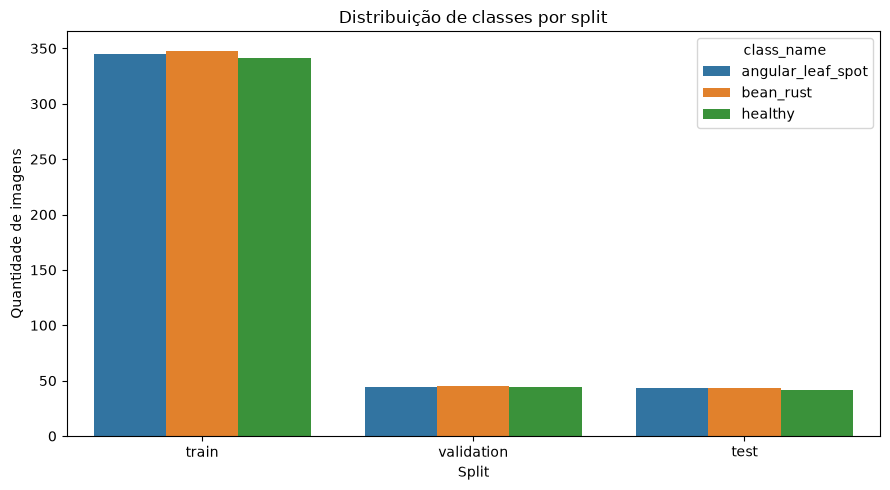

In [7]:
distribution_fig = plt.figure(figsize=(9, 5))
sns.barplot(data=distribution, x='split', y='count', hue='class_name')
plt.title('Distribuição de classes por split')
plt.xlabel('Split')
plt.ylabel('Quantidade de imagens')
plt.tight_layout()
plt.show()

## 4. Inspeção visual de amostras

A inspeção visual ajuda a verificar resolução, enquadramento, iluminação e variabilidade antes de definir augmentation e arquitetura de rede.

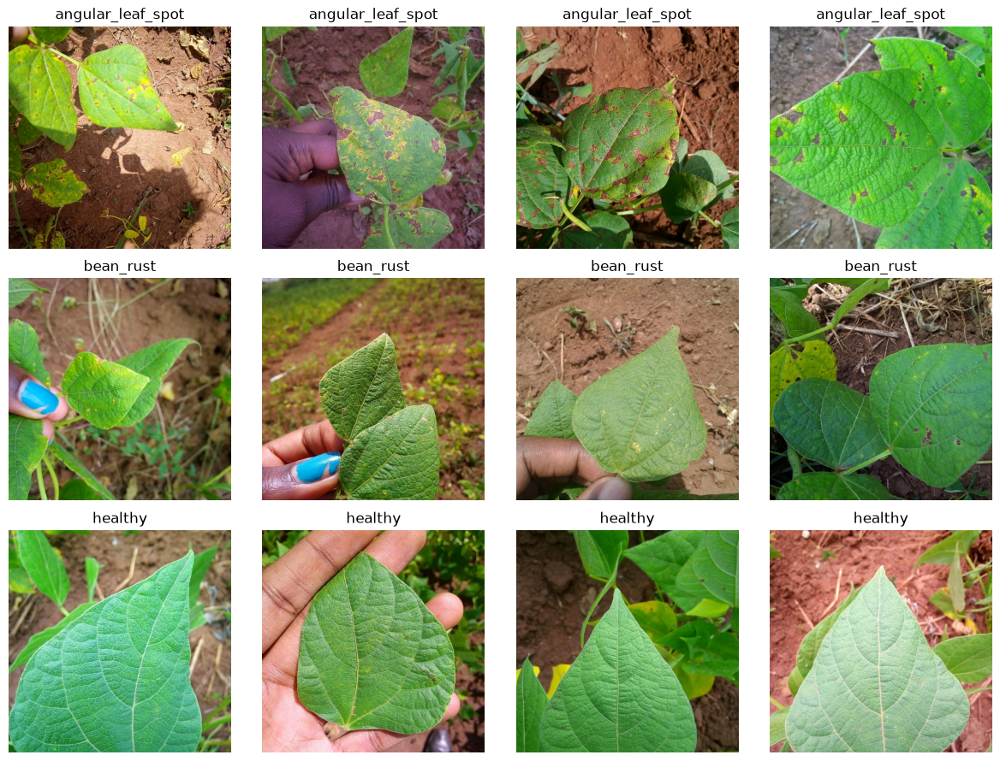

In [8]:
samples_fig, axes = plt.subplots(3, 4, figsize=(12, 9))
train_labels = np.asarray(dataset['train']['labels'])
for row, class_id in enumerate(range(len(labels))):
    indices = np.flatnonzero(train_labels == class_id)[:4]
    class_samples = [dataset['train'][int(index)] for index in indices]
    for col, sample in enumerate(class_samples):
        axes[row, col].imshow(sample['image'])
        axes[row, col].set_title(labels[class_id])
        axes[row, col].axis('off')
samples_fig.tight_layout()
plt.show()

## 5. Pré-processamento e aumento de dados

As imagens são convertidas para RGB, redimensionadas para 224 × 224 e normalizadas para o intervalo `[0, 1]`. O treino é embaralhado. Validação e teste mantêm a ordem original para associar cada predição à imagem e ao rótulo correspondentes.

O pipeline produz dois conjuntos de treino. A referência utiliza apenas o pré-processamento. A segunda condição incorpora espelhamento horizontal, rotação de até 15°, variação de brilho de até 0,10 na escala normalizada e contraste com fator entre 0,85 e 1,15. As transformações representam variações de orientação e iluminação observadas na análise exploratória. O pipeline preserva o enquadramento completo das folhas para manter as regiões com lesões.

In [9]:
IMAGE_SIZE = DEFAULT_IMAGE_SIZE
BATCH_SIZE = 32

splits = make_beans_splits(dataset, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, seed=SEED)
train_ds, val_ds, test_ds = (splits[key] for key in ("train", "validation", "test"))
train_aug_ds = make_tf_dataset(
    dataset["train"], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, seed=SEED, augment=True
)

In [10]:
images, y = next(iter(train_ds))
print('batch images:', images.shape)
print('batch labels:', y.shape)
print('min pixel:', float(images.numpy().min()))
print('max pixel:', float(images.numpy().max()))

batch images: (32, 224, 224, 3)
batch labels: (32,)
min pixel: 0.0
max pixel: 1.0


## 6. Verificação do pipeline

A verificação cobre a quantidade de imagens e lotes, o mapeamento das classes, o formato dos tensores, a faixa dos pixels e a ordem dos rótulos na validação e no teste.

In [11]:
expected_sizes = {"train": 1034, "validation": 133, "test": 128}
assert {key: len(dataset[key]) for key in splits} == expected_sizes
assert labels == ["angular_leaf_spot", "bean_rust", "healthy"]

for key, batches in splits.items():
    assert int(batches.cardinality()) == (expected_sizes[key] + BATCH_SIZE - 1) // BATCH_SIZE
    batch_images, targets = next(iter(batches))
    assert batch_images.shape == (BATCH_SIZE, *DEFAULT_IMAGE_SIZE, 3)
    assert batch_images.dtype == tf.float32 and targets.dtype == tf.int32
    tf.debugging.assert_greater_equal(batch_images, 0.0)
    tf.debugging.assert_less_equal(batch_images, 1.0)
    if key != "train":
        ordered_targets = np.concatenate([batch.numpy() for _, batch in batches])
        np.testing.assert_array_equal(ordered_targets, list(dataset[key]["labels"]))
    print(key, len(dataset[key]), batch_images.shape)

aug_images, aug_targets = next(iter(train_aug_ds))
assert train_aug_ds.cardinality().numpy() == train_ds.cardinality().numpy()
assert aug_images.shape == (BATCH_SIZE, *IMAGE_SIZE, 3)
assert aug_images.dtype == tf.float32 and aug_targets.dtype == tf.int32
tf.debugging.assert_greater_equal(aug_images, 0.0)
tf.debugging.assert_less_equal(aug_images, 1.0)
print("Treino com aumento de dados:", aug_images.shape)

print(dict(enumerate(labels)))

train 1034 (32, 224, 224, 3)
validation 133 (32, 224, 224, 3)
test 128 (32, 224, 224, 3)
Treino com aumento de dados: (32, 224, 224, 3)
{0: 'angular_leaf_spot', 1: 'bean_rust', 2: 'healthy'}


## 7. Registro das partições

As tabelas com o resumo dos splits e a distribuição das classes são registradas em `data/processed/`.

In [12]:
project_root = Path.cwd() if Path("pyproject.toml").is_file() else Path.cwd().parent
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
distribution.to_csv(output_dir / 'class_distribution.csv', index=False)
summary.to_csv(output_dir / 'split_summary.csv', index=False)
print('Metadados salvos em data/processed/.')

Metadados salvos em data/processed/.


## 8. Efeito das transformações nas imagens

Cada coluna apresenta a mesma folha após o pré-processamento e após o aumento de dados. Os rótulos são preservados nas duas condições.

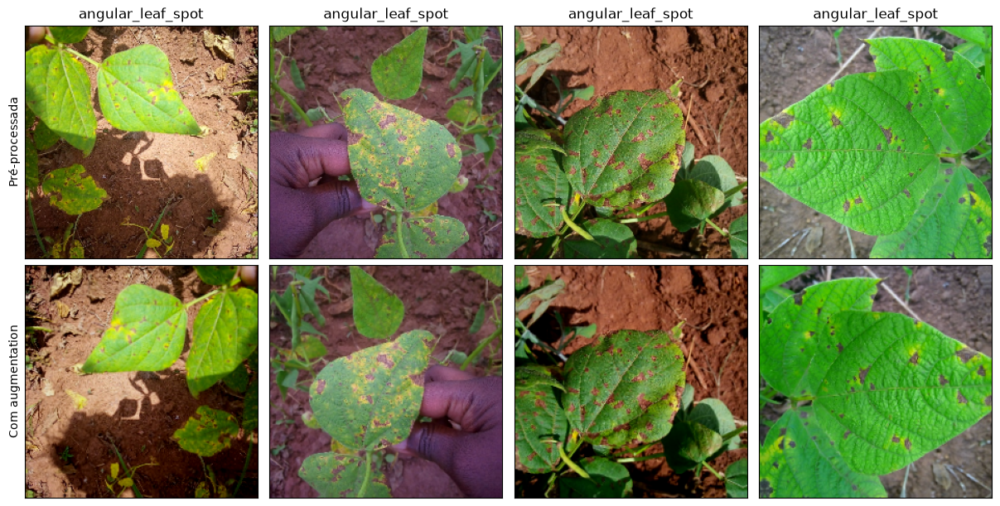

In [13]:
sample = dataset["train"].select(range(4))
original, target = next(iter(make_tf_dataset(sample, batch_size=4, shuffle=False)))
augmented, augmented_target = next(iter(
    make_tf_dataset(sample, batch_size=4, shuffle=False, seed=SEED, augment=True)
))
tf.debugging.assert_equal(target, augmented_target)

fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
for column, label in enumerate(target.numpy()):
    axes[0, column].imshow(original[column].numpy())
    axes[0, column].set_title(labels[label])
    axes[1, column].imshow(augmented[column].numpy())
    for axis in axes[:, column]:
        axis.set_xticks([])
        axis.set_yticks([])
axes[0, 0].set_ylabel("Pré-processada")
axes[1, 0].set_ylabel("Com augmentation")
plt.show()

---


# Parte II — Análise exploratória de dados (EDA)

_Origem: `notebooks/02_eda.ipynb`_


**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Este notebook cobre a análise visual e estatística das três classes (`angular_leaf_spot`, `bean_rust` e `healthy`), com o objetivo de embasar as decisões de pré-processamento, data augmentation e modelagem das próximas etapas.

## 1. Objetivo da análise
A EDA busca responder quatro perguntas que impactam diretamente a modelagem:

1. As classes estão balanceadas entre treino, validação e teste?
2. As imagens têm propriedades homogêneas (resolução, brilho, contraste)?
3. Existe diferença de cor entre folhas saudáveis e doentes que um modelo possa explorar?
4. Há duplicatas ou vazamento de dados entre os splits, que inflariam as métricas?


## 2. Base analisada

A análise abrange 1.295 fotografias de folhas de feijão, distribuídas nos três splits oficiais do Beans.

In [ ]:
import hashlib
from pathlib import Path

from IPython.display import display

notebook_dir = Path.cwd()
if (notebook_dir / "notebooks").is_dir():
    notebook_dir = notebook_dir / "notebooks"

required = ("dataset", "labels", "output_dir", "distribution_fig", "samples_fig", "pd", "plt", "sns")
missing = [name for name in required if name not in globals()]
assert not missing, (
    "Notebook consolidado: execute antes a Parte I (ingestão). Faltando: " + ", ".join(missing)
)

FIG_DIR = notebook_dir.parent / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("EDA: insumos da Parte I disponíveis | figuras em", FIG_DIR)


[consolidado] ponte da Parte II sem %run\n

In [2]:
print(dataset)
print("Classes:", labels)

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


## 3. Distribuição das classes por split
Um desbalanceamento forte tornaria a acurácia uma métrica enganosa e exigiria cuidados como pesos de classe ou reamostragem.

**Observações:**
- As três classes estão praticamente equilibradas em todos os splits: treino com 345, 348 e 341 imagens, validação com 44, 45 e 44, e teste com 43, 43 e 42. Cada classe representa cerca de 33% de cada split.
- A divisão é de aproximadamente 80% / 10% / 10% (1034, 133 e 128 imagens).
- Não há necessidade de pesos de classe nem de reamostragem, e a acurácia global não é enganosa neste caso. Ainda assim, o F1-macro e a matriz de confusão mostram em que classes o modelo erra.
- Uma única imagem altera a acurácia em 0,75 ponto percentual na validação e 0,78 no teste. Diferenças dessa ordem correspondem a apenas uma classificação.

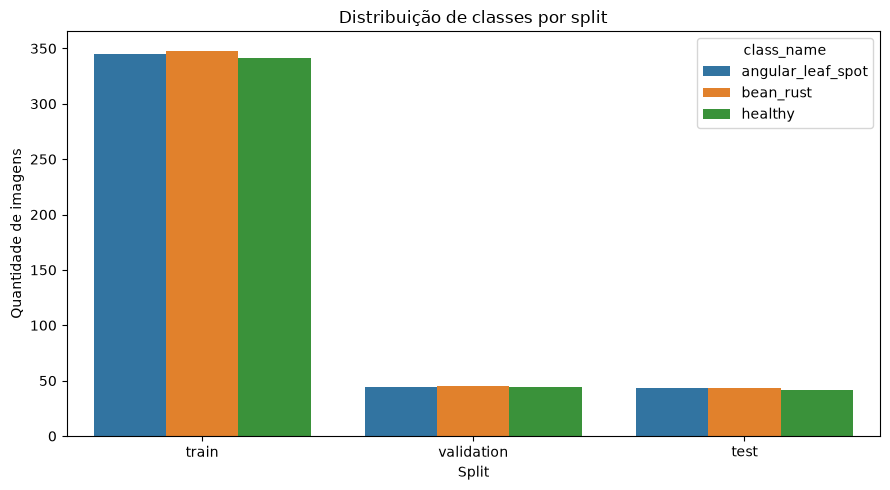

In [3]:
distribution_fig.savefig(FIG_DIR / "distribuicao_classes.png", dpi=150)
display(distribution_fig)

## 4. Inspeção visual das amostras
A grade apresenta os quatro primeiros exemplos de treino de cada classe.

**Observações:**
- São fotografias de campo, não imagens de laboratório: o fundo é solo avermelhado, mato e outras folhas, e em vários casos há uma mão segurando a folha. A folha aparece em enquadramentos, escalas e orientações bem diferentes, e a iluminação varia (sol direto, sombra projetada, tons mais escuros).
- `healthy` tem folhas de verde uniforme, sem manchas.
- `angular_leaf_spot` apresenta lesões bem visíveis, marrom-avermelhadas ou escuras, espalhadas pela folha e, em vários exemplos, cercadas por um halo amarelado.
- `bean_rust` apresenta, nestes exemplos, sinais mais discretos: pontos pequenos amarelos ou marrons, esparsos, sobre folhas predominantemente verdes. Pode ser mais difícil de distinguir de `healthy` do que `angular_leaf_spot`.
- As lesões ocupam uma área pequena da imagem, e a redução para 224 × 224 pode apagar parte desse detalhe, principalmente em `bean_rust`.
- Folhas saudáveis às vezes aparecem ao lado de folhas amareladas ou manchadas ao fundo, o que pode confundir o modelo.
- Mãos, unhas pintadas e o tom do solo variam entre as fotos e não estão ligados à doença. O modelo pode aprender esses elementos como atalho, e a augmentation (rotação, flip, brilho e contraste) ajuda a reduzir essa dependência. O Grad-CAM do notebook 05 permite verificar isso.


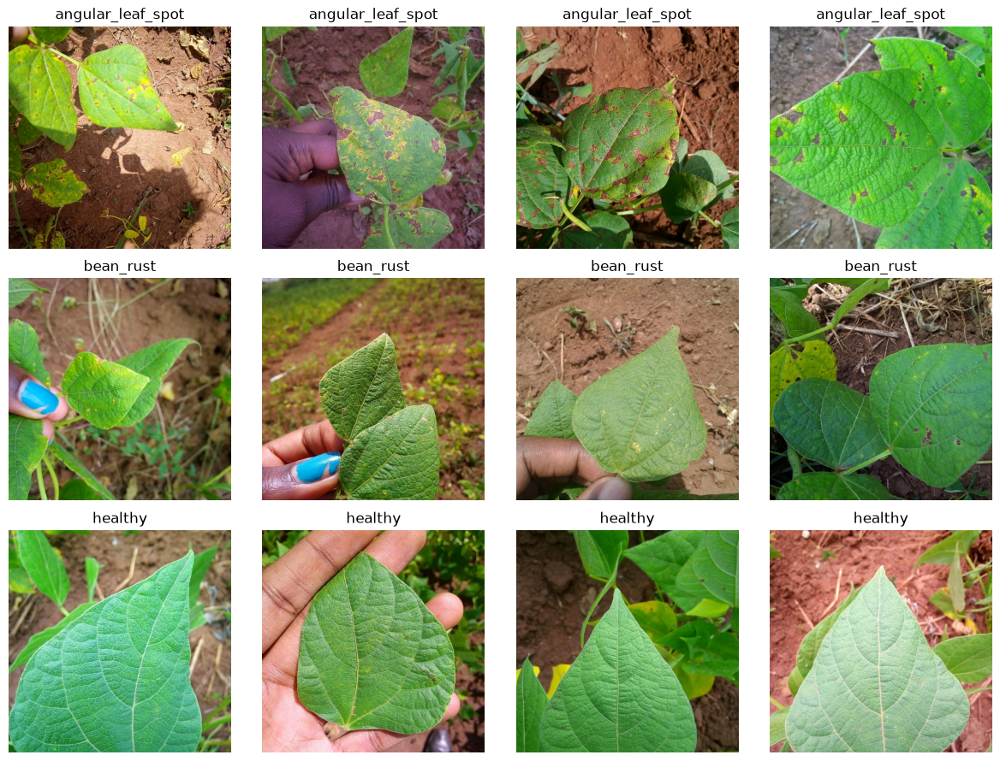

In [4]:
samples_fig.savefig(FIG_DIR / "amostras_por_classe.png", dpi=150)
display(samples_fig)

## 5. Propriedades das imagens
Calculamos, para todas as imagens dos três splits, a resolução original, a média dos canais R, G e B, o brilho (média em tons de cinza) e o contraste (desvio padrão em tons de cinza). Esses valores alimentam as análises seguintes e justificam o redimensionamento adotado na etapa 1 (224 × 224).

**Observações:**
- Todas as imagens têm a mesma resolução original, 500 × 500 pixels. Por serem quadradas, o redimensionamento para 224 × 224 não distorce a proporção da imagem.
- O brilho médio varia pouco entre as classes (de 0,42 a 0,46), mas o desvio padrão de cerca de 0,08 dentro de cada classe indica variação de iluminação entre as fotos.
- Os valores calculados aqui servem de referência para conferir a normalização usada no pipeline da etapa 1.

In [ ]:
def img_stats(img):
    a = np.asarray(img.convert("RGB"), dtype=np.float32) / 255
    g = a.mean(axis=2)
    return dict(w=img.width, h=img.height,
                R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean(),
                brilho=g.mean(), contraste=g.std())

rows = []
for split in dataset:
    for ex in dataset[split]:
        d = img_stats(ex["image"])
        d["split"] = split
        d["classe"] = labels[ex["labels"]]
        rows.append(d)
stats = pd.DataFrame(rows)

print(stats[["w", "h"]].drop_duplicates())
display(stats.groupby("classe")[["R", "G", "B", "brilho", "contraste"]].agg(["mean", "std"]).round(3))

## 6. Brilho e contraste por classe
A variação de iluminação entre fotos de campo é um dos principais desafios do problema. Se brilho e contraste variam bastante dentro de cada classe, o modelo precisa ser robusto a isso, o que justifica augmentation de brilho e contraste.

**Observações:**
- **Brilho:** as medianas são próximas entre as classes (cerca de 0,43 a 0,46), com `healthy` ligeiramente mais clara. Dentro de cada classe, porém, a variação é grande: os valores vão de aproximadamente 0,2 a 0,7, ou seja, há fotos bem escuras e fotos bem claras em todas as classes.
- **Contraste:** as medianas ficam entre cerca de 0,15 e 0,18, com `angular_leaf_spot` mais baixa e `healthy` mais alta. Os intervalos se sobrepõem bastante, e a faixa total vai de cerca de 0,08 a 0,28.
- **Outliers:** são poucos. Aparecem alguns pontos isolados de contraste alto em `bean_rust` (cerca de 0,28) e um em `healthy`, e um ponto de brilho baixo em `angular_leaf_spot`.
- A variação dentro de cada classe é maior do que a diferença entre elas. Isso indica que brilho e contraste refletem principalmente as condições de captura (sol, sombra, câmera), e não a doença, e justifica augmentation de brilho e contraste.

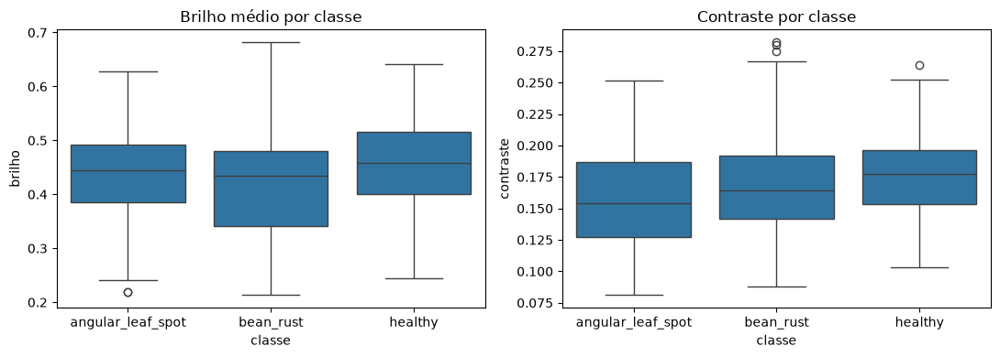

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=stats, x="classe", y="brilho", ax=ax[0]); ax[0].set_title("Brilho médio por classe")
sns.boxplot(data=stats, x="classe", y="contraste", ax=ax[1]); ax[1].set_title("Contraste por classe")
plt.tight_layout()
plt.savefig(FIG_DIR / "brilho_contraste.png", dpi=150)
plt.show()

## 7. Cor média por classe
As doenças alteram a coloração da folha, então a cor pode ser um sinal discriminativo. Ao mesmo tempo, um modelo que dependa demais da cor pode falhar com mudanças de iluminação ou de câmera, o que reforça a importância da augmentation.

**Observações:**
- `healthy` tem o maior verde (G ≈ 0,56) e o maior azul (B ≈ 0,34) entre as classes.
- `bean_rust` tem o menor verde (G ≈ 0,47), praticamente igual ao vermelho (R ≈ 0,48), o que combina com as manchas marrons e amareladas.
- `angular_leaf_spot` tem o maior vermelho (R ≈ 0,50) e o menor azul (B ≈ 0,29).
- A diferença de G entre `healthy` e `bean_rust` (cerca de 0,09) é da ordem de um desvio padrão (cerca de 0,085). Nos demais canais, as diferenças entre classes são menores que o desvio padrão. A cor média é, portanto, um sinal fraco, e as classes se sobrepõem bastante.
- A média é calculada sobre a imagem inteira, incluindo solo, mãos e outras folhas. Parte da diferença pode vir do fundo e não da folha, e isso só pode ser verificado com técnicas de explicabilidade, como o Grad-CAM do notebook 05.


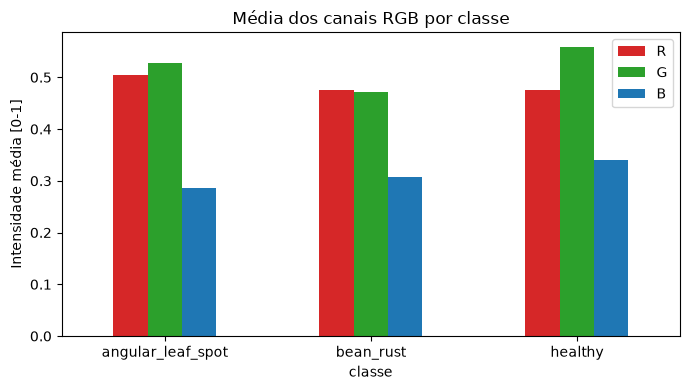

In [ ]:
cor = stats.groupby("classe")[["R", "G", "B"]].mean()
cor.plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], figsize=(7, 4))
plt.title("Média dos canais RGB por classe")
plt.ylabel("Intensidade média [0-1]")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "cor_media_classe.png", dpi=150)
plt.show()

## 8. Duplicatas e vazamento entre splits
Imagens idênticas em treino e teste fazem o modelo ser avaliado em dados que ele já viu, inflando as métricas. Comparamos o hash MD5 de cada imagem dentro de cada split e entre os splits. O método detecta apenas cópias exatas, não imagens parecidas.

**Resultado:**
- Nenhuma duplicata interna em treino (1034 imagens), validação (133) ou teste (128).
- Nenhuma imagem em comum entre treino e validação, treino e teste, ou validação e teste.

**Conclusão:** os três splits são independentes quanto a cópias exatas, e as métricas de validação e teste não são inflacionadas por imagens repetidas. A checagem não cobre fotos diferentes da mesma planta ou da mesma folha, que podem existir em uma base coletada em campo. Isso é uma limitação conhecida, e o dataset não traz informação para verificá-la.

In [ ]:
def md5(img):
    return hashlib.md5(img.tobytes()).hexdigest()

hashes = {s: [md5(ex["image"]) for ex in dataset[s]] for s in dataset}

for s, h in hashes.items():
    print(f"{s}: {len(h)} imagens, {len(h) - len(set(h))} duplicatas internas")

print("treino ∩ validação:", len(set(hashes["train"]) & set(hashes["validation"])))
print("treino ∩ teste:", len(set(hashes["train"]) & set(hashes["test"])))
print("validação ∩ teste:", len(set(hashes["validation"]) & set(hashes["test"])))

train: 1034 imagens, 0 duplicatas internas
validation: 133 imagens, 0 duplicatas internas
test: 128 imagens, 0 duplicatas internas
treino ∩ validação: 0
treino ∩ teste: 0
validação ∩ teste: 0


## 9. Implicações para data augmentation e modelagem

| Achado da EDA | Decisão proposta |
|---|---|
| Brilho e contraste variam muito dentro de cada classe (brilho de cerca de 0,2 a 0,7) | Augmentation de brilho e contraste |
| Fotos de campo, com folhas em enquadramentos, escalas e orientações diferentes | Rotação, flip horizontal e, se o grupo quiser testar, zoom ou recorte aleatório |
| Classes equilibradas (cerca de 33% cada) | Sem pesos de classe nem reamostragem; reportar acurácia global, F1-macro e matriz de confusão |
| Validação e teste pequenos (133 e 128 imagens) | Tratar diferenças pequenas entre modelos com cautela, pois cada imagem vale cerca de 0,75 ponto percentual |
| Cor média separa pouco as classes e o fundo (solo, mãos) varia | Usar augmentation para reduzir dependência do fundo e verificar com Grad-CAM no notebook 05 |
| Nenhum vazamento entre splits | Manter os splits originais do dataset |

Ponto a discutir: as imagens originais têm 500 × 500 pixels e as lesões ocupam uma área pequena. O redimensionamento para 224 × 224 reduz o detalhe das manchas, e vale testar uma resolução maior se o baseline tiver dificuldade com as classes doentes.

## 10. Conclusões e próximos passos
**Principais achados:**
- O dataset é bem equilibrado: 1034, 133 e 128 imagens, com cerca de 33% de cada classe em cada split.
- Todas as imagens têm 500 × 500 pixels, e a iluminação varia bastante dentro de cada classe.
- A cor média difere entre as classes, mas de forma modesta em relação à variação interna, então não deve ser suficiente por si só.
- Não há duplicatas internas nem vazamento entre treino, validação e teste.

**Próximos passos:** treinar o baseline com o pipeline da etapa 1 e aplicar a augmentation da seção 10, avaliar com as métricas do desafio e, no notebook 05, usar Grad-CAM para verificar se o modelo olha para a folha ou para o fundo.


In [ ]:
stats.to_csv(output_dir / "image_stats.csv", index=False)
print("Estatísticas salvas em data/processed/image_stats.csv")

Estatísticas salvas em data/processed/image_stats.csv


---


# Parte III — Modelagem baseline e treinamento

_Origem: `notebooks/03_baseline_model.ipynb`_


**Data Challenge | Desafio 1: Classificação de doenças em folhas**


## 1. Problema e objetivo

Classificação multiclasse de imagens (`angular_leaf_spot`, `bean_rust` ou `healthy`), com imagens `224 × 224` e pixels em `[0, 1]`, vindas do pipeline do 01.

Objetivos:

1. construir uma CNN pequena como **baseline**, treinada do zero;
2. treiná-la sem e com augmentation e medir o efeito;
3. gerar as curvas de aprendizado e avaliar em treino, validação e teste.

## 2. Continuação do notebook 01

No notebook consolidado, os insumos vêm das partes anteriores (sem reexecutar `%run`). A célula abaixo apenas valida o estado da sessão.


In [ ]:
from pathlib import Path
from IPython import get_ipython

notebook_dir = Path.cwd()
if (notebook_dir / 'notebooks').is_dir():
    notebook_dir = notebook_dir / 'notebooks'

required = [
    'dataset', 'labels', 'IMAGE_SIZE', 'SEED', 'set_global_seed',
    'train_ds', 'train_aug_ds', 'val_ds', 'test_ds', 'project_root', 'output_dir',
]
missing = [name for name in required if name not in globals()]
assert not missing, (
    'Notebook consolidado: execute antes as Partes I–II. Faltando: ' + ', '.join(missing)
)
print('Baseline: insumos das partes anteriores disponíveis')


[consolidado] ponte da Parte III sem %run\n

## 3. Setup específico do baseline

Só o que o 01 não tinha: Keras e a pasta das figuras (`reports/figures/`). Os artefatos vão para `output_dir` (`data/processed/`). O 01 já verifica a cardinalidade e a ordem de validação e teste, então não repetimos essas checagens.

In [2]:
import json
import time

from IPython.display import display
from matplotlib.ticker import MaxNLocator
from tensorflow import keras
from tensorflow.keras import layers

ARTIFACTS_DIR = output_dir  # data/processed, definido no notebook 01
FIGURES_DIR = project_root / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 4. Arquitetura do baseline

- **3 blocos** `Conv2D (3×3, ReLU) → MaxPooling2D`, com 16, 32 e 64 filtros;
- **`GlobalAveragePooling2D`** no lugar de `Flatten`, para reduzir parâmetros e overfitting;
- **`Dropout(0.3)`** e **`Dense(3, softmax)`**.

A arquitetura é a mesma nas duas condições; só muda o conjunto de treino.

In [3]:
def build_baseline_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape),
            layers.Conv2D(16, 3, padding='same', activation='relu'),
            layers.MaxPooling2D(),
            layers.Conv2D(32, 3, padding='same', activation='relu'),
            layers.MaxPooling2D(),
            layers.Conv2D(64, 3, padding='same', activation='relu'),
            layers.MaxPooling2D(),
            layers.GlobalAveragePooling2D(),
            layers.Dropout(0.3),
            layers.Dense(num_classes, activation='softmax'),
        ],
        name='baseline_cnn',
    )
    return model


set_global_seed(SEED, deterministic=True)
preview_model = build_baseline_cnn(input_shape=IMAGE_SIZE + (3,), num_classes=len(labels))
preview_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Treinamento nas duas condições

- **Referência** (`train_ds`): só pré-processamento;
- **Com augmentation** (`train_aug_ds`): espelhamento horizontal, rotação de até 15°, brilho de até 0,10 e contraste entre 0,85 e 1,15.

In [4]:
EPOCHS = 200  # teto de segurança: o early stopping decide quando parar
PATIENCE = 10
LEARNING_RATE = 1e-3

CONDITIONS = {
    'baseline': {'name': 'Baseline (referência)', 'train_data': train_ds},
    'baseline_aug': {'name': 'Baseline + augmentation', 'train_data': train_aug_ds},
}
runs = {}


def train_condition(key):
    condition = CONDITIONS[key]

    set_global_seed(SEED, deterministic=True)
    model = build_baseline_cnn(input_shape=IMAGE_SIZE + (3,), num_classes=len(labels))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'],
    )
    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True
    )

    start = time.perf_counter()
    history = model.fit(
        condition['train_data'],
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stopping],
        shuffle=False,  # o treino já vem embaralhado do pipeline do 01
        verbose=2,
    )
    train_time_s = time.perf_counter() - start

    history_df = pd.DataFrame(history.history)
    history_df.insert(0, 'epoch', range(1, len(history_df) + 1))
    best_epoch = int(history_df.loc[history_df['val_loss'].idxmin(), 'epoch'])
    stopped_by = 'early stopping' if early_stopping.stopped_epoch > 0 else 'teto de épocas'

    runs[key] = {
        'model': model,
        'history': history_df,
        'best_epoch': best_epoch,
        'stopped_by': stopped_by,
        'train_time_s': train_time_s,
    }
    print(
        f"{condition['name']}: {len(history_df)} épocas, melhor época {best_epoch}, "
        f"parou por {stopped_by}, {train_time_s:.1f} s"
    )

**Condição de referência** (`train_ds`, sem augmentation):

In [5]:
train_condition('baseline')

Epoch 1/200
33/33 - 15s - 446ms/step - accuracy: 0.3540 - loss: 1.0924 - val_accuracy: 0.5338 - val_loss: 1.0633
Epoch 2/200
33/33 - 12s - 376ms/step - accuracy: 0.5174 - loss: 1.0272 - val_accuracy: 0.5865 - val_loss: 0.9417
Epoch 3/200
33/33 - 13s - 385ms/step - accuracy: 0.5203 - loss: 0.9780 - val_accuracy: 0.5639 - val_loss: 0.9327
Epoch 4/200
33/33 - 12s - 353ms/step - accuracy: 0.5503 - loss: 0.9447 - val_accuracy: 0.5263 - val_loss: 0.9003
Epoch 5/200
33/33 - 11s - 326ms/step - accuracy: 0.5851 - loss: 0.8943 - val_accuracy: 0.6466 - val_loss: 0.8354
Epoch 6/200
33/33 - 11s - 324ms/step - accuracy: 0.5919 - loss: 0.8965 - val_accuracy: 0.6541 - val_loss: 0.8418
Epoch 7/200
33/33 - 11s - 319ms/step - accuracy: 0.6035 - loss: 0.8704 - val_accuracy: 0.5414 - val_loss: 0.8372
Epoch 8/200
33/33 - 11s - 344ms/step - accuracy: 0.6122 - loss: 0.8498 - val_accuracy: 0.6466 - val_loss: 0.7725
Epoch 9/200
33/33 - 11s - 339ms/step - accuracy: 0.6441 - loss: 0.8408 - val_accuracy: 0.6692 - 

**Condição com augmentation** (`train_aug_ds`):

In [6]:
train_condition('baseline_aug')

Epoch 1/200
33/33 - 19s - 580ms/step - accuracy: 0.3714 - loss: 1.0904 - val_accuracy: 0.3759 - val_loss: 1.0537
Epoch 2/200
33/33 - 17s - 521ms/step - accuracy: 0.4855 - loss: 1.0304 - val_accuracy: 0.5113 - val_loss: 0.9660
Epoch 3/200
33/33 - 18s - 533ms/step - accuracy: 0.5348 - loss: 0.9717 - val_accuracy: 0.5338 - val_loss: 0.9146
Epoch 4/200
33/33 - 18s - 540ms/step - accuracy: 0.5445 - loss: 0.9522 - val_accuracy: 0.6090 - val_loss: 0.9013
Epoch 5/200
33/33 - 18s - 543ms/step - accuracy: 0.5812 - loss: 0.9158 - val_accuracy: 0.6241 - val_loss: 0.8703
Epoch 6/200
33/33 - 18s - 532ms/step - accuracy: 0.5861 - loss: 0.9182 - val_accuracy: 0.5113 - val_loss: 0.9084
Epoch 7/200
33/33 - 19s - 590ms/step - accuracy: 0.6006 - loss: 0.9148 - val_accuracy: 0.6541 - val_loss: 0.8367
Epoch 8/200
33/33 - 19s - 566ms/step - accuracy: 0.6151 - loss: 0.8786 - val_accuracy: 0.5263 - val_loss: 0.8875
Epoch 9/200
33/33 - 17s - 507ms/step - accuracy: 0.6199 - loss: 0.8617 - val_accuracy: 0.6090 - 

## 6. Curvas de aprendizado

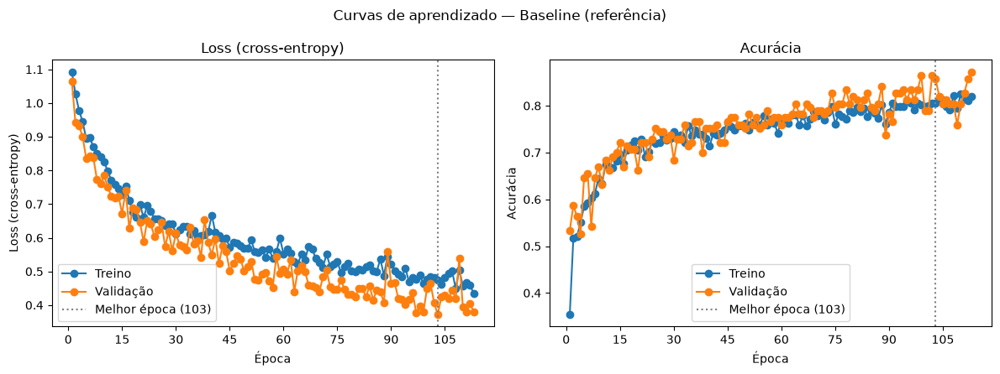

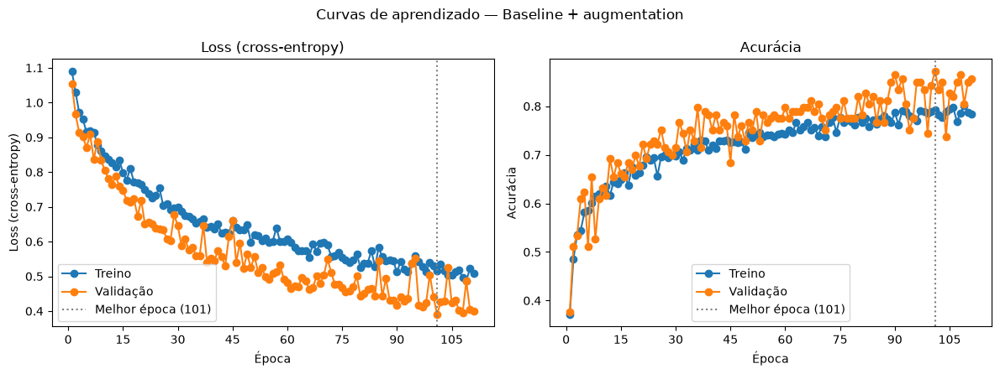

In [7]:
def plot_learning_curves(history_df, title, save_path=None):
    best_epoch = int(history_df.loc[history_df['val_loss'].idxmin(), 'epoch'])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    panels = [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]
    for ax, (metric, ylabel) in zip(axes, panels):
        ax.plot(history_df['epoch'], history_df[metric], marker='o', label='Treino')
        ax.plot(history_df['epoch'], history_df[f'val_{metric}'], marker='o', label='Validação')
        ax.axvline(best_epoch, color='gray', linestyle=':', label=f'Melhor época ({best_epoch})')
        ax.set_title(ylabel)
        ax.set_xlabel('Época')
        ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()

    fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return best_epoch


for key, run in runs.items():
    plot_learning_curves(
        run['history'],
        title=f"Curvas de aprendizado — {CONDITIONS[key]['name']}",
        save_path=FIGURES_DIR / f'{key}_learning_curves.png',
    )

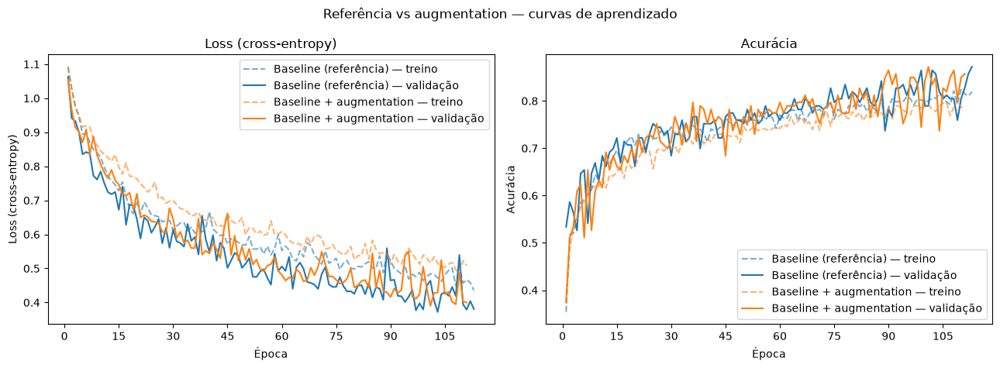

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
panels = [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]
colors = {'baseline': 'tab:blue', 'baseline_aug': 'tab:orange'}

for ax, (metric, ylabel) in zip(axes, panels):
    for key, run in runs.items():
        name = CONDITIONS[key]['name']
        hist = run['history']
        ax.plot(hist['epoch'], hist[metric], color=colors[key], linestyle='--', alpha=0.6,
                label=f'{name} — treino')
        ax.plot(hist['epoch'], hist[f'val_{metric}'], color=colors[key],
                label=f'{name} — validação')
    ax.set_title(ylabel)
    ax.set_xlabel('Época')
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()

fig.suptitle('Referência vs augmentation — curvas de aprendizado')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'baseline_vs_augmentation_curves.png', dpi=150, bbox_inches='tight')
plt.show()

Resumo numérico de cada condição: melhor época, motivo da parada e gap treino–validação.

In [9]:
summary_rows = []
for key, run in runs.items():
    hist = run['history']
    best = hist.loc[hist['epoch'] == run['best_epoch']].iloc[0]
    summary_rows.append(
        {
            'condição': CONDITIONS[key]['name'],
            'épocas executadas': len(hist),
            'parou por': run['stopped_by'],
            'melhor época': run['best_epoch'],
            'loss treino': best['loss'],
            'loss validação': best['val_loss'],
            'acurácia treino': best['accuracy'],
            'acurácia validação': best['val_accuracy'],
            'gap acurácia (treino − val.)': best['accuracy'] - best['val_accuracy'],
        }
    )
curve_summary = pd.DataFrame(summary_rows).set_index('condição')
display(curve_summary.round(4))

for key, run in runs.items():
    if run['stopped_by'] == 'teto de épocas':
        print(
            f"Atenção: '{CONDITIONS[key]['name']}' chegou ao teto de {EPOCHS} épocas "
            f"(melhor época: {run['best_epoch']}). Se a melhor época ficou perto do fim, "
            'o treino foi cortado pelo limite.'
        )

,épocas executadas,parou por,melhor época,loss treino,loss validação,acurácia treino,acurácia validação,gap acurácia (treino − val.)
condição,,,,,,,,
Baseline (referência),113,early stopping,103,0.4731,0.3722,0.8056,0.8571,-0.0515
Baseline + augmentation,111,early stopping,101,0.5160,0.3903,0.7921,0.8722,-0.0801


## 7. Avaliação final e comparação

Avaliamos cada modelo (com os pesos da melhor época) em treino, validação e teste.

In [10]:
EVAL_SPLITS = {'train': train_ds, 'val': val_ds, 'test': test_ds}

metrics = {}
for key, run in runs.items():
    result = {
        'model': CONDITIONS[key]['name'],
        'params': int(run['model'].count_params()),
        'epochs_run': int(len(run['history'])),
        'best_epoch': run['best_epoch'],
        'stopped_by': run['stopped_by'],
        'train_time_s': round(float(run['train_time_s']), 1),
    }
    for split, split_ds in EVAL_SPLITS.items():
        loss, accuracy = run['model'].evaluate(split_ds, verbose=0)
        result[f'{split}_loss'] = float(loss)
        result[f'{split}_accuracy'] = float(accuracy)
    metrics[key] = result

eval_summary = pd.DataFrame(metrics.values()).set_index('model')
eval_summary[
    ['train_accuracy', 'val_accuracy', 'test_accuracy', 'train_loss', 'val_loss', 'test_loss']
].round(4)

,train_accuracy,val_accuracy,test_accuracy,train_loss,val_loss,test_loss
model,,,,,,
Baseline (referência),0.8114,0.8571,0.8125,0.4426,0.3722,0.4220
Baseline + augmentation,0.8095,0.8722,0.8047,0.4470,0.3903,0.4205


In [11]:
ref, aug = metrics['baseline'], metrics['baseline_aug']

print('Diferença entre as condições (augmentation − referência):')
for split, split_name in [('val', 'validação'), ('test', 'teste')]:
    n_images = len(dataset['validation' if split == 'val' else 'test'])
    delta_acc = aug[f'{split}_accuracy'] - ref[f'{split}_accuracy']
    delta_loss = aug[f'{split}_loss'] - ref[f'{split}_loss']
    print(
        f'- {split_name}: acurácia {delta_acc * 100:+.2f} p.p. '
        f'(≈ {delta_acc * n_images:+.1f} imagens) | loss {delta_loss:+.4f} '
        '(loss negativa = melhora)'
    )

Diferença entre as condições (augmentation − referência):
- validação: acurácia +1.50 p.p. (≈ +2.0 imagens) | loss +0.0181 (loss negativa = melhora)
- teste: acurácia -0.78 p.p. (≈ -1.0 imagens) | loss -0.0015 (loss negativa = melhora)


## 8. Salvando os resultados

In [12]:
for key, run in runs.items():
    run['history'].to_csv(ARTIFACTS_DIR / f'{key}_history.csv', index=False)
    (ARTIFACTS_DIR / f'{key}_metrics.json').write_text(
        json.dumps(metrics[key], indent=2, ensure_ascii=False), encoding='utf-8'
    )
    run['model'].save(ARTIFACTS_DIR / f'{key}.keras')

eval_summary.to_csv(ARTIFACTS_DIR / 'baseline_comparison.csv')

print('Resultados salvos em data/processed/:')
print(sorted(path.name for path in ARTIFACTS_DIR.glob('baseline*')))

Resultados salvos em data/processed/:
['baseline.keras', 'baseline_aug.keras', 'baseline_aug_history.csv', 'baseline_aug_metrics.json', 'baseline_comparison.csv', 'baseline_history.csv', 'baseline_metrics.json']


---


# Parte IV — Métricas oficiais do baseline

_Origem: `notebooks/04_baseline_metrics.ipynb`_


**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Este notebook reúne a avaliação por classe e as métricas oficiais do baseline, além das conclusões e dificuldades.

São avaliadas duas condições:
- **Baseline (referência):** modelo treinado sem data augmentation.
- **Baseline + augmentation:** modelo treinado com data augmentation.

A avaliação utiliza o conjunto de teste e os modelos salvos pelo notebook 03.


## 1. Preparação do ambiente e carregamento dos dados

No notebook consolidado, os insumos vêm das partes anteriores (sem reexecutar `%run`). A célula abaixo apenas valida o estado da sessão.


In [ ]:
from pathlib import Path

notebook_dir = Path.cwd()
if (notebook_dir / 'notebooks').is_dir():
    notebook_dir = notebook_dir / 'notebooks'

required = ['dataset', 'labels', 'test_ds', 'output_dir', 'project_root']
missing = [name for name in required if name not in globals()]
assert not missing, (
    'Notebook consolidado: execute antes as Partes I–III. Faltando: ' + ', '.join(missing)
)
print('Classes:', labels)
print('Imagens no conjunto de teste:', len(dataset['test']))


[consolidado] ponte da Parte IV sem %run\n

## 2. Carregamento dos modelos baseline

Os modelos precisam ter sido salvos anteriormente pela seção 8 do notebook 03, na pasta `data/processed/`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

ARTIFACTS_DIR = output_dir

model_paths = {
    'baseline': ARTIFACTS_DIR / 'baseline.keras',
    'baseline_aug': ARTIFACTS_DIR / 'baseline_aug.keras',
}

missing_models = [str(path) for path in model_paths.values() if not path.exists()]
assert not missing_models, (
    'Não encontrei os modelos salvos. Execute primeiro o notebook 03 até a seção 8. '
    'Arquivos ausentes: ' + ', '.join(missing_models)
)

models = {
    'baseline': keras.models.load_model(model_paths['baseline']),
    'baseline_aug': keras.models.load_model(model_paths['baseline_aug']),
}

condition_names = {
    'baseline': 'Baseline (referência)',
    'baseline_aug': 'Baseline + augmentation',
}

print('Modelos carregados com sucesso.')

Modelos carregados com sucesso.


## 3. Avaliação por classe e métricas oficiais

Além da acurácia geral, esta etapa avalia as duas condições utilizando as três métricas definidas para o desafio: Acurácia Global, F1-Score Macro e Matriz de Confusão.

A avaliação é realizada sobre o conjunto de teste, que não foi utilizado durante o treinamento nem na escolha dos pesos do modelo.

A análise por classe permite identificar quais doenças são classificadas corretamente com maior frequência e quais apresentam maior dificuldade de identificação.

In [3]:
y_true = np.array(dataset['test']['labels'])
predictions = {}
results = {}

for key, model in models.items():
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    predictions[key] = y_pred

    accuracy = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro')
    results[key] = {
        'accuracy': float(accuracy),
        'f1_macro': float(f1_macro),
    }

    print(f"===== {condition_names[key]} =====")
    print(f"Acurácia Global: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"F1-Score Macro: {f1_macro:.4f}")
    print("\nRelatório por classe:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=labels,
        digits=4,
        zero_division=0,
    ))

import json

official_metrics = {
    'labels': list(labels),
    'results': results,
    'classification_reports': {
        key: classification_report(
            y_true,
            predictions[key],
            target_names=labels,
            digits=4,
            zero_division=0,
            output_dict=True,
        )
        for key in predictions
    },
    'confusion_matrices': {
        key: confusion_matrix(y_true, predictions[key]).tolist()
        for key in predictions
    },
}
metrics_path = ARTIFACTS_DIR / 'baseline_official_metrics.json'
metrics_path.write_text(json.dumps(official_metrics, indent=2), encoding='utf-8')
print(f'Métricas oficiais salvas em: {metrics_path}')

===== Baseline (referência) =====
Acurácia Global: 0.8125 (81.25%)
F1-Score Macro: 0.8093

Relatório por classe:
                   precision    recall  f1-score   support

angular_leaf_spot     0.7358    0.9070    0.8125        43
        bean_rust     0.8182    0.6279    0.7105        43
          healthy     0.9048    0.9048    0.9048        42

         accuracy                         0.8125       128
        macro avg     0.8196    0.8132    0.8093       128
     weighted avg     0.8189    0.8125    0.8085       128



===== Baseline + augmentation =====
Acurácia Global: 0.8047 (80.47%)
F1-Score Macro: 0.8055

Relatório por classe:
                   precision    recall  f1-score   support

angular_leaf_spot     0.7826    0.8372    0.8090        43
        bean_rust     0.7381    0.7209    0.7294        43
          healthy     0.9000    0.8571    0.8780        42

         accuracy                         0.8047       128
        macro avg     0.8069    0.8051    0.8055       128
     weighted avg     0.8062    0.8047    0.8049       128

Métricas oficiais salvas em: D:\dev\bean-leaf-disease-challenge\data\processed\baseline_official_metrics.json


### 3.1 Matriz de confusão

A matriz de confusão permite visualizar a quantidade de classificações corretas e incorretas para cada classe. Os valores da diagonal principal representam os acertos, enquanto os valores fora da diagonal representam as classificações incorretas.

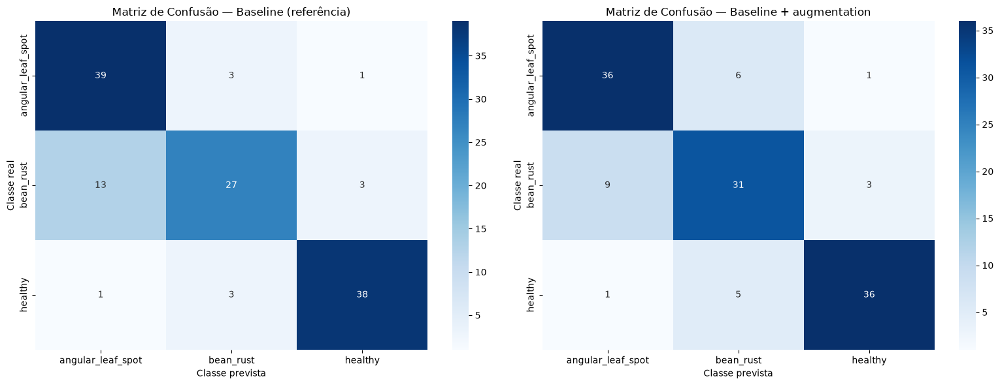

In [4]:
fig, axes = plt.subplots(1, len(predictions), figsize=(8 * len(predictions), 6))
axes = np.atleast_1d(axes)

for ax, (key, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_title(f"Matriz de Confusão — {condition_names[key]}")
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')

plt.tight_layout()
figures_dir = project_root / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(
    figures_dir / 'baseline_confusion_matrix.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

### 3.2 Interpretação dos resultados

No conjunto de **teste**, a condição de referência ficou ligeiramente à frente: acurácia **81,25%** e F1-macro **0,8093**, contra **80,47%** e **0,8055** com augmentation (diferença de ~1 imagem em 128). Na **validação**, contudo, o augmentation vence (**87,22%** vs **85,71%**), e é essa regra — definida no notebook 01 — que mantém o `baseline_aug` como modelo de referência das próximas etapas.

Por classe, o ganho mais claro do augmentation está em `bean_rust`: o recall sobe de **0,6279** para **0,7209** (27 → 31 acertos). Em troca, `angular_leaf_spot` cai de **0,9070** para **0,8372** e `healthy` de **0,9048** para **0,8571**. As matrizes de confusão confirmam o trade-off: a referência erra sobretudo `bean_rust` → `angular_leaf_spot` (13 casos); com augmentation esses erros caem para 9, mas aumentam os de `angular_leaf_spot` → `bean_rust` (3 → 6) e `healthy` → `bean_rust` (3 → 5).

Em resumo, o augmentation não eleva a acurácia/F1 de teste neste treino único, mas melhora o recall da classe mais difícil (`bean_rust`) e a validação — coerente com a EDA e com a escolha do modelo para Grad-CAM e Transfer Learning.

## 4. Conclusões e dificuldades

**Conclusões:**
- Treinamos do zero uma CNN pequena (23.779 parâmetros) em duas condições. A referência parou por early stopping na época 113 (melhor época 103, `val_loss` 0,3722); a condição com augmentation, na época 111 (melhor época 101, `val_loss` 0,3903). Nenhuma chegou ao teto de 200 épocas.
- Acurácia de validação e teste: **85,71%** e **81,25%** (referência); **87,22%** e **80,47%** (augmentation), muito acima do acaso (33%). F1-macro no teste: **0,8093** vs **0,8055**.
- Neste treino único o augmentation ganha na validação (+1,51 p.p.) e perde levemente no teste (−0,78 p.p., ≈ 1 imagem). O benefício mais claro é o recall de `bean_rust` (0,6279 → 0,7209). Não dá para atribuir o resultado só à augmentation: cada condição foi treinada uma vez.
- Pela regra do 01 (escolher pela validação), o **baseline + augmentation** segue como referência para Grad-CAM (notebook 05) e Transfer Learning (Entrega 2).

**Dificuldades:**
- **Quantidade de imagens:** o conjunto de teste possui apenas 128 imagens, o que limita a estabilidade das métricas. Cada imagem representa aproximadamente 0,78 ponto percentual da acurácia.
- **Confusão entre doenças:** a troca principal continua entre `angular_leaf_spot` e `bean_rust`.
- **Variação das imagens:** diferenças de iluminação, enquadramento e fundos podem influenciar as classificações.
- **Detalhamento das lesões:** o redimensionamento das imagens para 224 × 224 pixels pode prejudicar a identificação de lesões pequenas.
- **Generalização:** os resultados obtidos não garantem o mesmo desempenho em imagens de outras lavouras ou em diferentes condições de captura.


---


# Parte V — Transfer Learning, Grad-CAM e Entrega 2

_Origem: `notebooks/05_transfer_learning_gradcam.ipynb`_


**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Continuação dos notebooks 01–04. Esta etapa cobre o estudo de arquitetura, o treino do MobileNetV2 (Entrega 2) e o Grad-CAM:

1. **Estudo de arquitetura (Parte A).** Comparar MobileNetV2, EfficientNetB0 e ResNet50 e justificar a escolha.
2. **Grad-CAM no baseline (Parte B).** Verificar no `baseline_aug` se o modelo olha para a folha/lesões ou para o fundo (hipótese da EDA, notebook 02).
3. **Treino MobileNetV2 (Parte C — Entrega 2).** Feature extraction → fine-tuning, métricas oficiais vs baseline, Grad-CAM no modelo final e discussão de deploy.


## 1. Continuação dos notebooks anteriores

No notebook consolidado, os insumos vêm das partes anteriores (sem reexecutar `%run`). A célula abaixo apenas valida o estado da sessão.


In [ ]:
from pathlib import Path
from tensorflow import keras

notebook_dir = Path.cwd()
if (notebook_dir / 'notebooks').is_dir():
    notebook_dir = notebook_dir / 'notebooks'
project_root = notebook_dir.parent
artifacts_dir = project_root / 'data' / 'processed'
baseline_aug_path = artifacts_dir / 'baseline_aug.keras'

gradcam_model = None
if 'runs' in globals() and 'baseline_aug' in globals().get('runs', {}):
    source = 'sessão (Parte III — runs)'
    gradcam_model = runs['baseline_aug']['model']
elif baseline_aug_path.is_file():
    source = 'data/processed/baseline_aug.keras'
else:
    raise FileNotFoundError(
        'Notebook consolidado: não encontrei baseline_aug.keras nem runs da Parte III.'
    )

required = [
    'SEED', 'set_global_seed', 'IMAGE_SIZE', 'labels', 'dataset',
    'train_ds', 'train_aug_ds', 'val_ds', 'test_ds', 'pd', 'plt', 'sns', 'np',
]
missing = [name for name in required if name not in globals()]
assert not missing, f'Variáveis indisponíveis: {missing}'

FIGURES_DIR = project_root / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('fonte do baseline + augmentation:', source)
print('classes:', labels)
print('imagens de teste:', len(dataset['test']))


[consolidado] ponte da Parte V sem %run\n

## 2. Setup específico da etapa 5

Importamos os helpers do pacote: catálogo `BACKBONES`, `build_transfer_model` / fine-tune e as funções de Grad-CAM. Fixamos a semente para seleção de exemplos e treino reprodutíveis.


In [2]:
import json
import time

from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from tensorflow import keras

from bean_leaf_disease.evaluation import (
    find_last_conv_layer,
    make_gradcam_heatmap,
    overlay_heatmap,
)
from bean_leaf_disease.models import (
    BACKBONES,
    build_transfer_model,
    count_trainable_weights,
    enable_finetune,
    get_backbone,
)

set_global_seed(SEED, deterministic=True)
ARTIFACTS_DIR = project_root / 'data' / 'processed'
print('figuras em:', FIGURES_DIR)
print('artefatos em:', ARTIFACTS_DIR)


figuras em: D:\dev\bean-leaf-disease-challenge\reports\figures
artefatos em: D:\dev\bean-leaf-disease-challenge\data\processed


## 3. Parte A — Estudo de arquiteturas de Transfer Learning

O baseline do notebook 03 é uma CNN pequena (23.779 parâmetros) treinada do zero, com cerca de 80–81% de acurácia no teste (notebook 04). O conjunto de treino tem apenas **1034 imagens**, e a EDA (notebook 02) mostrou que as lesões ocupam uma área pequena da folha e que o fundo (solo, mão) varia muito. Nesse cenário, treinar do zero uma rede grande tende a sofrer overfitting.

**Transfer Learning** contorna isso: usamos um backbone pré-treinado em ImageNet (1,2 milhão de imagens, 1000 classes) como **extrator de características**. As camadas convolucionais já aprenderam bordas, texturas e padrões que se transferem bem para folhas, e só treinamos um classificador leve no topo. É a abordagem padrão para datasets pequenos.

Comparamos três candidatas comuns, todas com entrada 224×224 (a mesma do pipeline da etapa 1).


In [3]:
tabela = pd.DataFrame(BACKBONES).T
tabela = tabela[['params_millions', 'size_mb', 'imagenet_top1', 'expects', 'note']]
tabela = tabela.rename(
    columns={
        'params_millions': 'parâmetros (M)',
        'size_mb': 'tamanho (MB)',
        'imagenet_top1': 'top-1 ImageNet',
        'expects': 'entrada esperada',
        'note': 'leitura para viabilidade',
    }
)
tabela['top-1 ImageNet'] = (tabela['top-1 ImageNet'].astype(float) * 100).round(1).astype(str) + '%'
with pd.option_context('display.max_colwidth', None):
    display(tabela)

,parâmetros (M),tamanho (MB),top-1 ImageNet,entrada esperada,leitura para viabilidade
MobileNetV2,3.5,14,71.3%,"[-1, 1]","Menor footprint. Projetado para dispositivos móveis/embarcados, adequado a inferência em campo. Treino rápido e menor risco de overfitting num dataset pequeno."
EfficientNetB0,5.3,29,77.1%,"[0, 255]","Melhor acurácia ImageNet entre as candidatas, ainda compacto. A normalização é interna ao modelo (espera pixels em [0, 255])."
ResNet50,25.6,98,74.9%,"caffe (BGR, centrado)",Arquitetura robusta e muito usada como referência. Maior e mais custosa; serve de teto de capacidade na comparação.


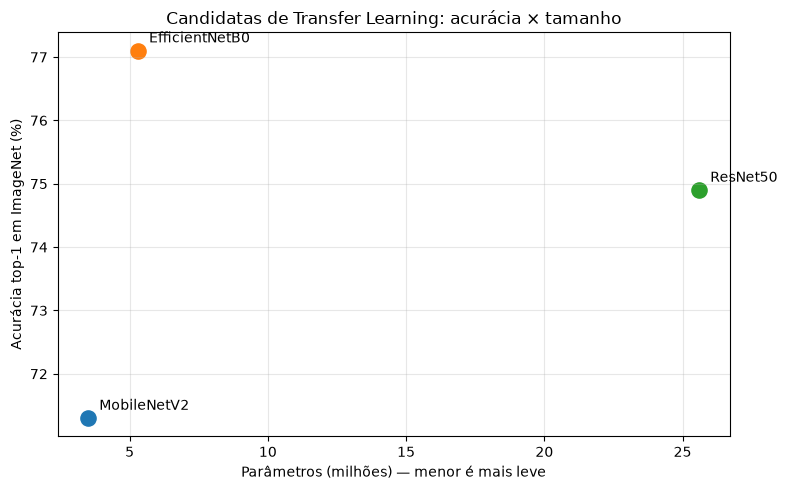

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, spec in BACKBONES.items():
    ax.scatter(spec['params_millions'], spec['imagenet_top1'] * 100, s=120)
    ax.annotate(
        name,
        (spec['params_millions'], spec['imagenet_top1'] * 100),
        textcoords='offset points', xytext=(8, 6),
    )
ax.set_xlabel('Parâmetros (milhões) — menor é mais leve')
ax.set_ylabel('Acurácia top-1 em ImageNet (%)')
ax.set_title('Candidatas de Transfer Learning: acurácia × tamanho')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_arquiteturas.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.1 Justificativa da escolha

As três candidatas superam com folga o baseline treinado do zero em ImageNet, mas a escolha para a Entrega 2 pesa **acurácia, custo e viabilidade operacional** (deploy em campo ou na agroindústria, tema pedido no enunciado da Entrega 2):

- **MobileNetV2 — escolha recomendada.** Menor footprint (3,5M parâmetros, 14 MB), projetado para dispositivos móveis/embarcados. É o mais adequado a inferência em campo (celular, borda) e o de menor risco de overfitting nas 1034 imagens de treino. Treina de forma viável em CPU com feature extraction + fine-tuning (Parte C).
- **EfficientNetB0 — alternativa de maior acurácia.** Melhor top-1 ImageNet (77,1%) ainda com tamanho moderado (5,3M, 29 MB). Fica como plano B se o MobileNetV2 não separar bem `bean_rust` de `angular_leaf_spot` (a confusão observada no notebook 04). Atenção: sua normalização é interna (espera pixels em [0, 255]).
- **ResNet50 — referência de capacidade.** Robusta e muito usada, mas grande (25,6M, 98 MB) e mais custosa, sem ganho claro de acurácia sobre a EfficientNetB0 aqui. Serve de teto de capacidade na comparação, não de candidata para deploy leve.

**Decisão:** **MobileNetV2** como extrator de características, com fine-tuning das camadas superiores na Parte C. A EfficientNetB0 permanece como plano B se a confusão `bean_rust` ↔ `angular_leaf_spot` não melhorar o suficiente.


### 3.2 Preview do pipeline (antes do treino)

`build_transfer_model` monta o modelo escolhido com o **mesmo topo do baseline** (GlobalAveragePooling2D → Dropout(0.3) → Dense softmax), para a comparação baseline × transfer learning ser justa. O pipeline da etapa 1 entrega pixels em [0, 1]; o construtor insere `Rescaling(255.0)` + o `preprocess_input` do backbone.

A célula abaixo só mostra a estrutura e a proporção de parâmetros congelados. O **treino de fato** (feature extraction + fine-tuning) está na Parte C.


In [5]:
preview_model = build_transfer_model('MobileNetV2', num_classes=len(labels), image_size=IMAGE_SIZE)

trainable, non_trainable = count_trainable_weights(preview_model)
print(f'Parâmetros treináveis (topo):   {trainable:,}')
print(f'Parâmetros congelados (backbone): {non_trainable:,}')
print(
    'Observe: com o backbone congelado, só o classificador do topo é treinado — '
    'poucos milhares de parâmetros, viável com 1034 imagens.'
)


Parâmetros treináveis (topo):   3,843
Parâmetros congelados (backbone): 2,257,984
Observe: com o backbone congelado, só o classificador do topo é treinado — poucos milhares de parâmetros, viável com 1034 imagens.


## 4. Parte B — Grad-CAM sobre o baseline + augmentation

O Grad-CAM destaca as regiões que mais pesaram na predição de uma classe. Aplicamos sobre o modelo **baseline + augmentation** do notebook 03 (o escolhido lá pela regra de seleção por validação) para responder: **o modelo olha para a folha ou para o fundo?**

Usamos a última **Conv2D** do baseline como alvo (`find_last_conv_layer` prioriza convolução, não o MaxPooling seguinte; mapa ~56×56×64).

In [6]:
# No caso (b) — modelo salvo em disco — ainda precisamos carregá-lo aqui.
if gradcam_model is None:
    gradcam_model = keras.models.load_model(baseline_aug_path)

last_conv = find_last_conv_layer(gradcam_model)
print('modelo Grad-CAM pronto | última camada convolucional (alvo):', last_conv)

modelo Grad-CAM pronto | última camada convolucional (alvo): conv2d_8


### 4.1 Seleção de exemplos

Escolhemos exemplos do conjunto de **teste** (não usado no treino): um acerto de cada classe e, para contraste, um **erro** — priorizando a confusão `bean_rust` ↔ `angular_leaf_spot` observada na matriz de confusão do notebook 04. Cada imagem é pré-processada do mesmo jeito que no treino (224×224, pixels em [0, 1]).


In [7]:
import tensorflow as tf

# Reconstrói as imagens de teste na ordem original, pré-processadas (224x224, [0,1]).
test_images = []
test_labels = []
for images, lbls in test_ds:
    test_images.append(images.numpy())
    test_labels.append(lbls.numpy())
test_images = np.concatenate(test_images)
test_labels = np.concatenate(test_labels)

# Predições do baseline_aug sobre o teste.
probs = gradcam_model.predict(test_images, verbose=0)
preds = probs.argmax(axis=1)

# Um acerto por classe + um erro (de preferência bean_rust <-> angular_leaf_spot).
selected = []
for class_id in range(len(labels)):
    hits = np.flatnonzero((test_labels == class_id) & (preds == class_id))
    if len(hits):
        selected.append(('acerto', int(hits[0])))

errors = np.flatnonzero(test_labels != preds)
if len(errors):
    pair = {labels.index('bean_rust'), labels.index('angular_leaf_spot')}
    priority = [i for i in errors if test_labels[i] in pair and preds[i] in pair]
    selected.append(('erro', int(priority[0] if priority else errors[0])))

for tag, idx in selected:
    print(f'{tag}: real={labels[test_labels[idx]]}, previsto={labels[preds[idx]]} (idx {idx})')

acerto: real=angular_leaf_spot, previsto=angular_leaf_spot (idx 0)
acerto: real=bean_rust, previsto=bean_rust (idx 43)
acerto: real=healthy, previsto=healthy (idx 86)
erro: real=angular_leaf_spot, previsto=bean_rust (idx 13)


### 4.2 Mapas de calor

Para cada exemplo: imagem original, mapa de calor sobreposto e o rótulo real/previsto. Vermelho = região que mais pesou na predição.

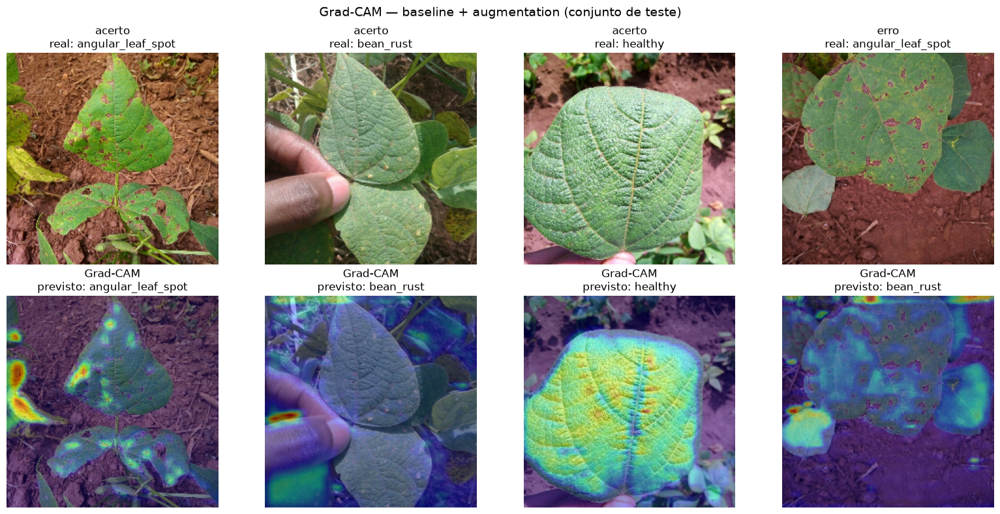

In [8]:
n = len(selected)
fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
axes = np.atleast_2d(axes)

for col, (tag, idx) in enumerate(selected):
    image = test_images[idx]
    img_batch = image[np.newaxis, ...]
    heatmap = make_gradcam_heatmap(img_batch, gradcam_model, last_conv, pred_index=int(preds[idx]))
    overlaid = overlay_heatmap(image, heatmap)

    real, previsto = labels[test_labels[idx]], labels[preds[idx]]
    axes[0, col].imshow(image)
    axes[0, col].set_title(f'{tag}\nreal: {real}')
    axes[1, col].imshow(overlaid)
    axes[1, col].set_title(f'Grad-CAM\nprevisto: {previsto}')
    for ax in axes[:, col]:
        ax.axis('off')

fig.suptitle('Grad-CAM — baseline + augmentation (conjunto de teste)', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'gradcam_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Leitura dos resultados

Nos quatro exemplos do teste (idxs 0, 43, 86 e 13), o Grad-CAM sobre `baseline_aug` mostra um quadro misto — em parte confirma a hipótese da EDA, em parte mostra aprendizado útil:

- **Acerto `angular_leaf_spot` (idx 0).** O vermelho/amarelo cai sobre a lâmina e coincide com lesões/furos da folha; o solo ao fundo fica frio. Aqui o modelo usa o sinal clínico esperado.
- **Acerto `bean_rust` (idx 43).** Há mão segurando a folha, e o hotspot principal concentra-se na **mão/polegar**, não nas pústulas. É o atalho de fundo/objeto que a EDA (notebook 02, seções 4 e 7) alertava: a predição pode estar certa pelo motivo errado.
- **Acerto `healthy` (idx 86).** A ativação cobre a superfície da folha (nervuras/lâmina) e pouco o solo — coerente com “folha sem padrão de doença”.
- **Erro `angular_leaf_spot` → `bean_rust` (idx 13).** O mapa ainda foca a folha e as manchas, não o chão; a falha parece ser de **discriminação entre sintomas parecidos**, não de atalho de fundo. Isso alinha com a matriz do notebook 04, onde a troca entre essas duas classes é a principal.

**Resolução.** O mapa vem da última Conv2D (~56×56), então indica regiões, não lesões milimétricas. Na Parte C, o Grad-CAM sobre MobileNetV2 (feature maps mais profundos) localiza melhor e permite checar se o Transfer Learning reduz a dependência de mão/fundo.

> Síntese: o baseline + augmentation às vezes olha para a folha (bons casos e o erro entre doenças), mas ainda pode ancorar em mão/contexto — motivação direta para Transfer Learning e para discutir confiabilidade em campo.


## 5. Parte C — Treino MobileNetV2 (Entrega 2)

Com a arquitetura escolhida na Parte A e o diagnóstico Grad-CAM da Parte B, treinamos o MobileNetV2 e comparamos com o baseline oficial (notebook 04).

Mesmo protocolo do notebook 03: teto de 200 épocas, early stopping com paciência 10, Adam. Usamos **augmentation** no treino (melhor validação no baseline e alinhado à EDA). Fine-tuning libera as últimas 40 camadas do MobileNetV2 com LR 1e-5. Depende das métricas oficiais do notebook 04 (`baseline_official_metrics.json`).


In [9]:
BACKBONE = 'MobileNetV2'
EPOCHS = 200
PATIENCE = 10
LR_HEAD = 1e-3
LR_FINETUNE = 1e-5
UNFREEZE_LAST = 40

baseline_official_path = ARTIFACTS_DIR / 'baseline_official_metrics.json'
assert baseline_official_path.exists(), (
    'Execute o notebook 04 antes para gerar baseline_official_metrics.json.'
)
baseline_official = json.loads(baseline_official_path.read_text(encoding='utf-8'))

print('Baseline (teste) já registrado:')
for key, row in baseline_official['results'].items():
    print(f"  {key}: acc={row['accuracy']:.4f} | f1_macro={row['f1_macro']:.4f}")


Baseline (teste) já registrado:
  baseline: acc=0.8125 | f1_macro=0.8093
  baseline_aug: acc=0.8047 | f1_macro=0.8055


### 5.1 Fase 1 — Feature extraction (backbone congelado)

Montamos o MobileNetV2 com `trainable_base=False`: só o topo (GAP → Dropout → Dense) é treinado. O pré-processamento ImageNet fica dentro do modelo (`Rescaling(255)` + `preprocess_input`), compatível com pixels `[0, 1]` do notebook 01.


In [10]:
set_global_seed(SEED, deterministic=True)
tl_model = build_transfer_model(
    BACKBONE,
    num_classes=len(labels),
    image_size=IMAGE_SIZE,
    trainable_base=False,
)
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_HEAD),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

trainable_n, frozen_n = count_trainable_weights(tl_model)
print(f'Backbone: {get_backbone(tl_model).name}')
print(f'Parâmetros treináveis (topo):   {trainable_n:,}')
print(f'Parâmetros congelados:          {frozen_n:,}')
tl_model.summary()

Backbone: mobilenetv2_1.00_224
Parâmetros treináveis (topo):   3,843
Parâmetros congelados:          2,257,984


Model: "transfer_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
early_stopping_fe = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
)

start_fe = time.perf_counter()
history_fe = tl_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping_fe],
    shuffle=False,
    verbose=2,
)
fe_time_s = time.perf_counter() - start_fe

history_fe_df = pd.DataFrame(history_fe.history)
history_fe_df.insert(0, 'epoch', range(1, len(history_fe_df) + 1))
history_fe_df['phase'] = 'feature_extraction'
best_fe_epoch = int(history_fe_df.loc[history_fe_df['val_loss'].idxmin(), 'epoch'])
stopped_fe = 'early stopping' if early_stopping_fe.stopped_epoch > 0 else 'teto de épocas'

print(
    f'Feature extraction: {len(history_fe_df)} épocas, melhor época {best_fe_epoch}, '
    f'parou por {stopped_fe}, {fe_time_s:.1f} s'
)
print(
    f"Melhor val_loss={history_fe_df.loc[history_fe_df['epoch'] == best_fe_epoch, 'val_loss'].iloc[0]:.4f} | "
    f"val_acc={history_fe_df.loc[history_fe_df['epoch'] == best_fe_epoch, 'val_accuracy'].iloc[0]:.4f}"
)

Epoch 1/200


33/33 - 33s - 1s/step - accuracy: 0.6132 - loss: 0.8386 - val_accuracy: 0.8271 - val_loss: 0.4856


Epoch 2/200


33/33 - 28s - 840ms/step - accuracy: 0.7901 - loss: 0.5185 - val_accuracy: 0.8421 - val_loss: 0.4039


Epoch 3/200


33/33 - 29s - 881ms/step - accuracy: 0.8221 - loss: 0.4325 - val_accuracy: 0.8647 - val_loss: 0.3393


... (113 outputs left out)

33/33 - 26s - 794ms/step - accuracy: 0.9449 - loss: 0.1446 - val_accuracy: 0.9023 - val_loss: 0.2052


Epoch 61/200


33/33 - 27s - 833ms/step - accuracy: 0.9468 - loss: 0.1436 - val_accuracy: 0.9248 - val_loss: 0.1748


Feature extraction: 61 épocas, melhor época 51, parou por early stopping, 1632.7 s
Melhor val_loss=0.1727 | val_acc=0.9173


### 5.2 Fase 2 — Fine-tuning (topo do backbone)

Liberamos as últimas 40 camadas do MobileNetV2 e recompilamos com LR 1e-5 para não destruir os pesos de ImageNet. O early stopping continua monitorando `val_loss`.


In [12]:
enable_finetune(tl_model, unfreeze_last=UNFREEZE_LAST)
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_FINETUNE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

trainable_ft, frozen_ft = count_trainable_weights(tl_model)
print(f'Após enable_finetune(unfreeze_last={UNFREEZE_LAST}):')
print(f'Parâmetros treináveis:     {trainable_ft:,}')
print(f'Parâmetros congelados:     {frozen_ft:,}')

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
)

start_ft = time.perf_counter()
history_ft = tl_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping_ft],
    shuffle=False,
    verbose=2,
)
ft_time_s = time.perf_counter() - start_ft

history_ft_df = pd.DataFrame(history_ft.history)
history_ft_df.insert(0, 'epoch', range(1, len(history_ft_df) + 1))
history_ft_df['phase'] = 'fine_tuning'
# Épocas contínuas na curva combinada (FE + FT).
history_ft_df['epoch_global'] = history_ft_df['epoch'] + len(history_fe_df)
best_ft_epoch = int(history_ft_df.loc[history_ft_df['val_loss'].idxmin(), 'epoch'])
stopped_ft = 'early stopping' if early_stopping_ft.stopped_epoch > 0 else 'teto de épocas'

print(
    f'Fine-tuning: {len(history_ft_df)} épocas, melhor época {best_ft_epoch}, '
    f'parou por {stopped_ft}, {ft_time_s:.1f} s'
)
print(
    f"Melhor val_loss={history_ft_df.loc[history_ft_df['epoch'] == best_ft_epoch, 'val_loss'].iloc[0]:.4f} | "
    f"val_acc={history_ft_df.loc[history_ft_df['epoch'] == best_ft_epoch, 'val_accuracy'].iloc[0]:.4f}"
)

Após enable_finetune(unfreeze_last=40):
Parâmetros treináveis:     1,685,379
Parâmetros congelados:     576,448
Epoch 1/200


33/33 - 45s - 1s/step - accuracy: 0.7950 - loss: 0.5864 - val_accuracy: 0.9248 - val_loss: 0.1751


Epoch 2/200


33/33 - 35s - 1s/step - accuracy: 0.8462 - loss: 0.3844 - val_accuracy: 0.9323 - val_loss: 0.1746


Epoch 3/200


33/33 - 34s - 1s/step - accuracy: 0.8878 - loss: 0.3198 - val_accuracy: 0.9248 - val_loss: 0.1835


... (15 outputs left out)

33/33 - 32s - 959ms/step - accuracy: 0.9217 - loss: 0.2092 - val_accuracy: 0.9173 - val_loss: 0.1896


Epoch 12/200


33/33 - 32s - 961ms/step - accuracy: 0.9420 - loss: 0.1465 - val_accuracy: 0.9173 - val_loss: 0.1832


Fine-tuning: 12 épocas, melhor época 2, parou por early stopping, 407.3 s
Melhor val_loss=0.1746 | val_acc=0.9323


### 5.3 Curvas de aprendizado


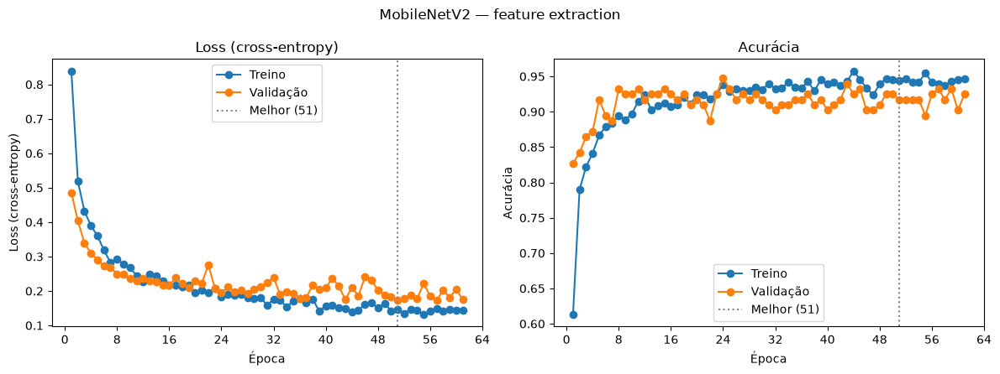

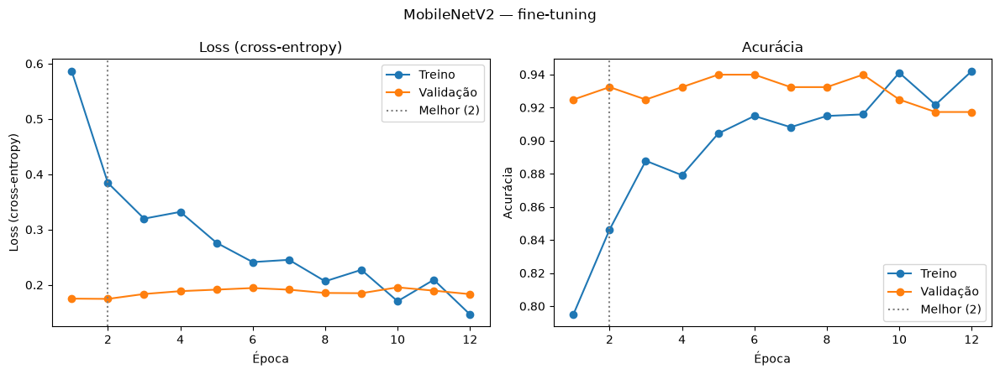

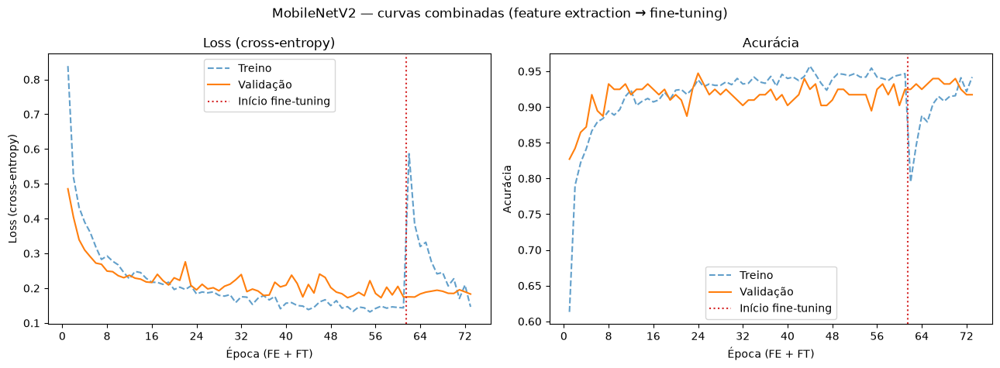

In [13]:
def plot_phase_curves(history_df, title, save_path=None, epoch_col='epoch'):
    best_epoch = int(history_df.loc[history_df['val_loss'].idxmin(), epoch_col])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (metric, ylabel) in zip(axes, [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]):
        ax.plot(history_df[epoch_col], history_df[metric], marker='o', label='Treino')
        ax.plot(history_df[epoch_col], history_df[f'val_{metric}'], marker='o', label='Validação')
        ax.axvline(best_epoch, color='gray', linestyle=':', label=f'Melhor ({best_epoch})')
        ax.set_title(ylabel)
        ax.set_xlabel('Época')
        ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_phase_curves(
    history_fe_df,
    'MobileNetV2 — feature extraction',
    FIGURES_DIR / 'tl_fe_learning_curves.png',
)
plot_phase_curves(
    history_ft_df,
    'MobileNetV2 — fine-tuning',
    FIGURES_DIR / 'tl_ft_learning_curves.png',
)

# Curva combinada
history_fe_plot = history_fe_df.copy()
history_fe_plot['epoch_global'] = history_fe_plot['epoch']
combined = pd.concat(
    [
        history_fe_plot[['epoch_global', 'loss', 'val_loss', 'accuracy', 'val_accuracy', 'phase']],
        history_ft_df[['epoch_global', 'loss', 'val_loss', 'accuracy', 'val_accuracy', 'phase']],
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
split_epoch = len(history_fe_df) + 0.5
for ax, (metric, ylabel) in zip(axes, [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]):
    ax.plot(combined['epoch_global'], combined[metric], linestyle='--', alpha=0.7, label='Treino')
    ax.plot(combined['epoch_global'], combined[f'val_{metric}'], label='Validação')
    ax.axvline(split_epoch, color='tab:red', linestyle=':', label='Início fine-tuning')
    ax.set_title(ylabel)
    ax.set_xlabel('Época (FE + FT)')
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
fig.suptitle('MobileNetV2 — curvas combinadas (feature extraction → fine-tuning)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_combined_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Avaliação oficial no teste e comparação com o baseline

Mesmas métricas do desafio (notebook 04): acurácia global, F1-macro e matriz de confusão no **teste**.


In [14]:
y_true = np.array(dataset['test']['labels'])
y_prob = tl_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

tl_accuracy = float(accuracy_score(y_true, y_pred))
tl_f1 = float(f1_score(y_true, y_pred, average='macro'))
tl_cm = confusion_matrix(y_true, y_pred)
tl_report = classification_report(
    y_true, y_pred, target_names=labels, digits=4, zero_division=0, output_dict=True
)

print('===== MobileNetV2 (fine-tuned) =====')
print(f'Acurácia Global: {tl_accuracy:.4f} ({tl_accuracy * 100:.2f}%)')
print(f'F1-Score Macro: {tl_f1:.4f}')
print('\nRelatório por classe:')
print(classification_report(y_true, y_pred, target_names=labels, digits=4, zero_division=0))

# evaluate splits
EVAL_SPLITS = {'train': train_ds, 'val': val_ds, 'test': test_ds}
split_metrics = {}
for split_name, split_ds in EVAL_SPLITS.items():
    loss, acc = tl_model.evaluate(split_ds, verbose=0)
    split_metrics[f'{split_name}_loss'] = float(loss)
    split_metrics[f'{split_name}_accuracy'] = float(acc)

print('Acurácias (evaluate):')
for split_name in ('train', 'val', 'test'):
    print(f"  {split_name}: {split_metrics[f'{split_name}_accuracy']:.4f}")

===== MobileNetV2 (fine-tuned) =====
Acurácia Global: 0.9141 (91.41%)
F1-Score Macro: 0.9109

Relatório por classe:
                   precision    recall  f1-score   support

angular_leaf_spot     0.8600    1.0000    0.9247        43
        bean_rust     1.0000    0.7442    0.8533        43
          healthy     0.9130    1.0000    0.9545        42

         accuracy                         0.9141       128
        macro avg     0.9243    0.9147    0.9109       128
     weighted avg     0.9244    0.9141    0.9105       128



Acurácias (evaluate):
  train: 0.9420
  val: 0.9323
  test: 0.9141


In [15]:
comparison_rows = []
for key, row in baseline_official['results'].items():
    name = 'Baseline (referência)' if key == 'baseline' else 'Baseline + augmentation'
    comparison_rows.append(
        {
            'model': name,
            'test_accuracy': row['accuracy'],
            'test_f1_macro': row['f1_macro'],
        }
    )
comparison_rows.append(
    {
        'model': 'MobileNetV2 (FE + fine-tune)',
        'test_accuracy': tl_accuracy,
        'test_f1_macro': tl_f1,
    }
)
comparison_df = pd.DataFrame(comparison_rows).set_index('model')
display(comparison_df.round(4))

best_baseline_acc = max(r['accuracy'] for r in baseline_official['results'].values())
best_baseline_f1 = max(r['f1_macro'] for r in baseline_official['results'].values())
print(
    f"Delta vs melhor baseline — acurácia: {(tl_accuracy - best_baseline_acc) * 100:+.2f} p.p. | "
    f"F1-macro: {(tl_f1 - best_baseline_f1) * 100:+.2f} p.p."
)

,test_accuracy,test_f1_macro
model,,
Baseline (referência),0.8125,0.8093
Baseline + augmentation,0.8047,0.8055
MobileNetV2 (FE + fine-tune),0.9141,0.9109


Delta vs melhor baseline — acurácia: +10.16 p.p. | F1-macro: +10.16 p.p.


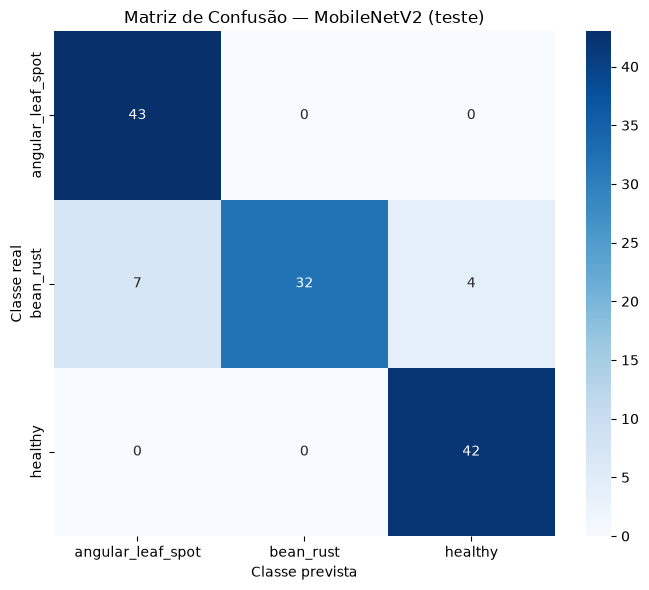

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    tl_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    ax=ax,
)
ax.set_title('Matriz de Confusão — MobileNetV2 (teste)')
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Grad-CAM no MobileNetV2

Mesma seleção da Parte B (um acerto por classe + erro `angular_leaf_spot` → `bean_rust`, quando existir), agora sobre o modelo de Transfer Learning.


camada alvo Grad-CAM: mobilenetv2_1.00_224


acerto: real=angular_leaf_spot, previsto=angular_leaf_spot (idx 0)
acerto: real=bean_rust, previsto=bean_rust (idx 43)
acerto: real=healthy, previsto=healthy (idx 86)
erro: real=bean_rust, previsto=healthy (idx 49)


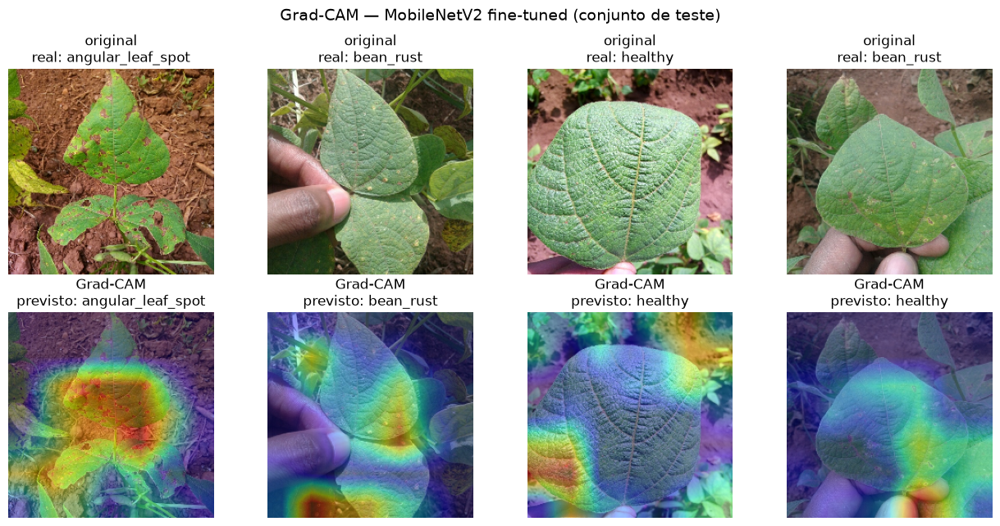

In [17]:
last_conv = find_last_conv_layer(tl_model)
print('camada alvo Grad-CAM:', last_conv)

# Materializa imagens de teste na mesma ordem dos rótulos.
images = []
for batch_x, _ in test_ds:
    for img in batch_x.numpy():
        images.append(img)
images = np.stack(images)

selected = []
for class_id, class_name in enumerate(labels):
    idxs = np.where((y_true == class_id) & (y_pred == class_id))[0]
    if len(idxs) == 0:
        idxs = np.where(y_true == class_id)[0]
    idx = int(idxs[0])
    selected.append((idx, class_name, labels[int(y_pred[idx])], bool(y_true[idx] == y_pred[idx])))

err = np.where((y_true == 0) & (y_pred == 1))[0]
if len(err) == 0:
    err = np.where(y_true != y_pred)[0]
if len(err):
    idx = int(err[0])
    selected.append((idx, labels[int(y_true[idx])], labels[int(y_pred[idx])], False))

for idx, real, previsto, ok in selected:
    tag = 'acerto' if ok else 'erro'
    print(f'{tag}: real={real}, previsto={previsto} (idx {idx})')

n = len(selected)
fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6.5))
for col, (idx, real, previsto, _) in enumerate(selected):
    img = images[idx]
    heatmap = make_gradcam_heatmap(img[None, ...], tl_model, last_conv)
    overlay = overlay_heatmap(img, heatmap)
    axes[0, col].imshow(np.clip(img, 0, 1))
    axes[0, col].set_title(f'original\nreal: {real}')
    axes[0, col].axis('off')
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f'Grad-CAM\nprevisto: {previsto}')
    axes[1, col].axis('off')
fig.suptitle('Grad-CAM — MobileNetV2 fine-tuned (conjunto de teste)', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'gradcam_transfer.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.1 Leitura do Grad-CAM (Transfer Learning)

Comparando com `gradcam_baseline.png` (Parte B), nos mesmos índices de acerto (0, 43, 86) e no primeiro erro do TL:

- **Acerto `angular_leaf_spot` (idx 0).** Hotspots sobre as lesões/necroses da lâmina; solo permanece frio — sinal clínico correto, como no baseline.
- **Acerto `bean_rust` (idx 43).** No baseline o vermelho caía na **mão/polegar**; no MobileNetV2 a mão fica fria e a ativação concentra-se em **manchas da folha**. Evidência de que o Transfer Learning reduziu o atalho de fundo da EDA.
- **Acerto `healthy` (idx 86).** Ativação na superfície/bordas da folha, pouco no fundo — coerente com “folha sem padrão de doença”.
- **Erro `bean_rust` → `healthy` (idx 49).** Ainda há ativação parcial nos dedos além da lâmina; sintomas mais leves foram lidos como saudáveis. A matriz confirma o residual: 7 `bean_rust`→`angular_leaf_spot` e 4→`healthy` (já sem erros em `angular_leaf_spot` nem em `healthy`).

**Síntese:** o mapa do backbone (~7×7×1280) localiza melhor que a CNN rasa e, no caso crítico da mão, o TL olha para a folha. Restam confusões em `bean_rust` com sintomas discretos.


## 8. Salvando artefatos


In [18]:
history_fe_df.to_csv(ARTIFACTS_DIR / 'transfer_fe_history.csv', index=False)
history_ft_df.to_csv(ARTIFACTS_DIR / 'transfer_ft_history.csv', index=False)
combined.to_csv(ARTIFACTS_DIR / 'transfer_combined_history.csv', index=False)

tl_metrics = {
    'model': 'MobileNetV2 (FE + fine-tune)',
    'backbone': BACKBONE,
    'params': int(tl_model.count_params()),
    'trainable_params_finetune': int(trainable_ft),
    'unfreeze_last': UNFREEZE_LAST,
    'fe_epochs_run': int(len(history_fe_df)),
    'fe_best_epoch': best_fe_epoch,
    'fe_stopped_by': stopped_fe,
    'fe_train_time_s': round(float(fe_time_s), 1),
    'ft_epochs_run': int(len(history_ft_df)),
    'ft_best_epoch': best_ft_epoch,
    'ft_stopped_by': stopped_ft,
    'ft_train_time_s': round(float(ft_time_s), 1),
    'train_time_s_total': round(float(fe_time_s + ft_time_s), 1),
    **split_metrics,
    'test_accuracy_sklearn': tl_accuracy,
    'test_f1_macro': tl_f1,
}
(ARTIFACTS_DIR / 'transfer_metrics.json').write_text(
    json.dumps(tl_metrics, indent=2, ensure_ascii=False),
    encoding='utf-8',
)

official = {
    'labels': list(labels),
    'results': {
        'transfer_mobilenetv2': {
            'accuracy': tl_accuracy,
            'f1_macro': tl_f1,
        }
    },
    'classification_reports': {
        'transfer_mobilenetv2': tl_report,
    },
    'confusion_matrices': {
        'transfer_mobilenetv2': tl_cm.tolist(),
    },
    'comparison_with_baseline': comparison_df.reset_index().to_dict(orient='records'),
}
(ARTIFACTS_DIR / 'transfer_official_metrics.json').write_text(
    json.dumps(official, indent=2, ensure_ascii=False),
    encoding='utf-8',
)
comparison_df.to_csv(ARTIFACTS_DIR / 'transfer_vs_baseline.csv')

tl_model.save(ARTIFACTS_DIR / 'transfer_mobilenetv2.keras')

print('Artefatos salvos:')
for pattern in ('transfer*', 'gradcam_transfer.png', 'tl_*.png'):
    matches = sorted(ARTIFACTS_DIR.glob(pattern)) + sorted(FIGURES_DIR.glob(pattern))
    for path in matches:
        print(' ', path.relative_to(project_root))

Artefatos salvos:
  data\processed\transfer_combined_history.csv
  data\processed\transfer_fe_history.csv
  data\processed\transfer_ft_history.csv
  data\processed\transfer_metrics.json
  data\processed\transfer_mobilenetv2.keras
  data\processed\transfer_official_metrics.json
  data\processed\transfer_vs_baseline.csv
  reports\figures\gradcam_transfer.png
  reports\figures\tl_arquiteturas.png
  reports\figures\tl_combined_learning_curves.png
  reports\figures\tl_confusion_matrix.png
  reports\figures\tl_fe_learning_curves.png
  reports\figures\tl_ft_learning_curves.png


## 9. Conclusões, dificuldades e viabilidade operacional

**Conclusões:**
- MobileNetV2 em duas fases: feature extraction **61** épocas (melhor 51) + fine-tuning **12** épocas (melhor 2, últimas 40 camadas, LR 1e-5), com augmentation e early stopping iguais ao baseline. Tempo total ~34 min nesta máquina (CPU).
- No teste: **91,41%** de acurácia e **F1-macro 0,9109** — **+10,16 p.p.** frente ao melhor baseline (81,25% / 0,8093). `angular_leaf_spot` e `healthy` ficam com recall 1,0; o gargalo residual é `bean_rust` (recall 0,7442).
- O Grad-CAM mostra ganho de confiabilidade: no mesmo acerto `bean_rust` (idx 43) em que o baseline olhava a mão, o TL foca as lesões da folha.

**Dificuldades:**
- Dataset pequeno (1034 treino / 128 teste): cada imagem de teste ≈ 0,78 p.p. de acurácia.
- `bean_rust` ainda confunde com `angular_leaf_spot` (7) e `healthy` (4) quando os sintomas são discretos.
- Fine-tuning longo em CPU com `deterministic=True` é lento (~27–35 s/época na FE); necessário para reprodutibilidade pedida no desafio.

**Viabilidade operacional (campo / agroindústria):**
- **Footprint:** ~2,3M parâmetros no modelo completo / backbone MobileNetV2 (~14 MB) — adequado a celular, edge GPU/NPU ou gateway na propriedade.
- **Latência:** inferência leve em 224×224; viável offline após export (TFLite / SavedModel).
- **Confiabilidade:** Grad-CAM + limiar de confiança e revisão agronômica amostral; o TL já reduz o atalho mão/fundo visto no baseline.
- **Limitações de deploy:** iluminação, cultivares e fundos fora do Beans pedem monitoramento e, se possível, calibração local ou segmentação da folha no pré-processamento.


---


# Encerramento — Entrega 2

Pipeline completo: ingestão → EDA → baseline → métricas oficiais → Transfer Learning (MobileNetV2) + Grad-CAM.

**Artefatos principais** em `data/processed/` e `reports/figures/`:
- `baseline.keras`, `baseline_aug.keras`, `baseline_official_metrics.json`
- `transfer_mobilenetv2.keras`, `transfer_official_metrics.json`, `transfer_vs_baseline.csv`
- `gradcam_baseline.png`, `gradcam_transfer.png`, `baseline_confusion_matrix.png`, `tl_confusion_matrix.png`
